VoltRelay Energy — Data Analytics Hackathon

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


1. Business Problem

2. Dataset Understanding

3. Data Cleaning

4. Network Performance

5. Service Failures & Customer Experience

6. Station & Geographic Analysis

7. Battery & Equipment Analysis

8. Pricing & Partner Economics

9. Rider Retention

10. Key Findings

# Key Findings and Business Recommendations

## 1. Key findings

### Finding 1: Network performance varies significantly by city
- Jaipur records the highest non-completion rate at 7.85%.
- Delhi NCR has the largest unsuccessful-event volume, with 56,528 events.
- Hyderabad follows with a 6.69% non-completion rate and 47,618 unsuccessful events.

### Finding 2: Gen1 stations show weaker performance
- Gen1 non-completion rate: 7.23%.
- Gen2 non-completion rate: 4.84%.
- Gen3 non-completion rate: 4.84%.
- All 10 highest-volume stations for unsuccessful events are Gen1.

### Finding 3: Gen1 has poorer ready-battery availability
- Gen1 zero-ready 2W battery hours: 2.34%.
- Gen2: 0.42%.
- Gen3: 0.26%.

This is a descriptive operational difference. Further investigation is needed before attributing failures directly to battery availability.

### Finding 4: Network performance deteriorates during April–June
- May 2024 non-completion rate: 12.27%.
- May 2025: 9.91%.
- June 2025: 8.55%.

The recurring deterioration warrants investigation. March–April 2025 timestamps require caution because of the documented firmware issue.

### Finding 5: Rider retention declines over time
For 9,686 riders signing up during January–December 2024:
- Month 0 retention: 97.47%.
- Month 1: 92.36%.
- Month 2: 82.60%.
- Month 6: 67.20%.

The largest decline occurs between months 1 and 2.

### Finding 6: Partner economics are concentrated
- FeastFly has the highest observed partner net revenue at approximately ₹3.27 crore.
- ZipDrop has an actual discount rate of 21.91%, compared with its original contractual discount of 12% and amended discount of 28%.
- Partner-linked transactions represent only part of the network. These revenue figures are not total company revenue or profit.

## 2. Business recommendations

### Priority 1: Audit and improve Gen1 stations
- Prioritize Gen1 stations with high unsuccessful-event volumes.
- Inspect charging equipment, firmware, maintenance records and battery availability.
- Evaluate upgrade feasibility using station-level cost and performance data.

### Priority 2: Focus operational intervention on Jaipur, Delhi NCR and Hyderabad
- Investigate Jaipur's high non-completion rate.
- Prioritize Delhi NCR for its large absolute unsuccessful-event volume.
- Review Hyderabad's station-level performance and equipment condition.

### Priority 3: Improve ready-battery availability
- Review inventory targets and battery replenishment procedures at Gen1 stations.
- Monitor zero-ready-battery hours and their relationship with unsuccessful swaps.
- Establish station-level operational alerts.

### Priority 4: Investigate April–June deterioration
- Compare staffing, demand, inventory, outages, weather and operational disruptions during these months.
- Check whether the same drivers explain the recurring pattern across years.
- Treat March–April 2025 timestamp data cautiously.

### Priority 5: Improve early rider engagement
- Investigate the decline between months 1 and 2.
- Review rider complaints, service interruptions and station accessibility.
- Test onboarding and early-engagement interventions, then measure cohort retention.

### Priority 6: Review partner discount economics
- Investigate the difference between contractual and actual discount rates.
- Evaluate partner-level net revenue alongside operating costs before making profitability decisions.

## 3. Overall conclusion

The analysis identifies meaningful differences in network performance across cities, charger generations, stations and rider cohorts. Gen1 infrastructure and selected high-burden cities are important operational priorities. Improving equipment reliability, battery availability and early rider experience may help strengthen network performance and customer retention.

These findings are observational and should guide further investigation and targeted operational testing rather than be interpreted as proof of causation.

11. Markdown cell

12. Business Recommendations

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/VoltRelay_Hackathon"

print("Folder exists:", os.path.exists(PROJECT_DIR))
print("Files found:")

for file in os.listdir(PROJECT_DIR):
    path = os.path.join(PROJECT_DIR, file)
    print(file, "|", round(os.path.getsize(path) / (1024**2), 2), "MB")

Folder exists: True
Files found:
batteries.csv | 0.6 MB
support_tickets.csv | 6.23 MB
riders.csv | 2.0 MB
stations.csv | 0.02 MB
city_daily_context.csv | 0.21 MB
fleet_partners.csv | 0.0 MB
station_hourly_status.csv | 103.33 MB
swap_events.csv.gz | 694.97 MB


In [ ]:
import os

SWAP_FILE = os.path.join(PROJECT_DIR, "swap_events.csv.gz")

with open(SWAP_FILE, "rb") as f:
    first_bytes = f.read(20)

print("First 20 bytes:", first_bytes)
print("File size (MB):", round(os.path.getsize(SWAP_FILE) / (1024**2), 2))

First 20 bytes: b'event_id,rider_id,st'
File size (MB): 694.97


In [ ]:
import pandas as pd

sample = pd.read_csv(
    SWAP_FILE,
    compression=None,
    nrows=10000
)

print("Sample shape:", sample.shape)

print("\nColumns:")
print(sample.columns.tolist())

print("\nData types:")
print(sample.dtypes)

print("\nFirst 5 rows:")
display(sample.head())

Sample shape: (10000, 22)

Columns:
['event_id', 'rider_id', 'station_id', 'event_ts', 'event_type', 'attempt_seq', 'queue_wait_sec', 'battery_in_id', 'battery_out_id', 'soc_in_pct', 'soh_in_pct', 'soc_out_pct', 'soh_out_pct', 'km_since_last_swap', 'tariff_code', 'list_price_inr', 'discount_inr', 'amount_charged_inr', 'payment_mode', 'energy_to_recharge_kwh', 'station_firmware', 'sync_mode']

Data types:
event_id                   object
rider_id                   object
station_id                 object
event_ts                   object
event_type                 object
attempt_seq                 int64
queue_wait_sec              int64
battery_in_id              object
battery_out_id             object
soc_in_pct                float64
soh_in_pct                float64
soc_out_pct               float64
soh_out_pct               float64
km_since_last_swap        float64
tariff_code                object
list_price_inr            float64
discount_inr              float64
amount_charged

,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,...,soh_out_pct,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode
0,SW-000000001,RD-1000003,STN-MUM-115,2024-01-01 11:10:56,swap_completed,1,88,BAT-2W-103542,BAT-2W-102547,15.0,...,98.9,80.4,PARTNER,60.0,6.0,54.0,partner_invoice,2.035,v3.2.1,realtime
1,SW-000000002,RD-1000004,STN-HYD-070,2024-01-01 17:13:06,swap_completed,1,148,BAT-2W-105296,BAT-2W-101923,8.3,...,98.2,66.1,PARTNER,60.0,9.0,51.0,partner_invoice,2.157,v3.2.0,realtime
2,SW-000000003,RD-1000005,STN-DEL-046,2024-01-01 20:15:14,swap_completed,1,307,BAT-2W-104732,BAT-2W-102492,11.5,...,99.1,66.6,STD,60.0,0.0,60.0,partner_invoice,2.039,v3.2.0,realtime
3,SW-000000004,RD-1000006,STN-JAI-135,2024-01-01 20:26:07,swap_completed,1,399,BAT-2W-103839,BAT-2W-103267,7.9,...,98.2,65.4,STD,60.0,0.0,60.0,partner_invoice,2.194,v3.2.0,realtime
4,SW-000000005,RD-1000012,STN-PUN-100,2024-01-01 21:13:07,swap_completed,1,201,BAT-2W-104056,BAT-2W-106218,10.5,...,99.9,73.8,STD,60.0,0.0,60.0,partner_invoice,1.971,v3.2.1,realtime


In [ ]:
import os

for filename in os.listdir(PROJECT_DIR):
    if "station" in filename.lower():
        path = os.path.join(PROJECT_DIR, filename)
        print(
            repr(filename),
            "|",
            round(os.path.getsize(path) / (1024**2), 2),
            "MB"
        )

'stations.csv' | 0.02 MB
'station_hourly_status.csv' | 103.33 MB


In [ ]:
STATUS_FILE = os.path.join(
    PROJECT_DIR,
    "station_hourly_status.csv"
)

status_sample = pd.read_csv(
    STATUS_FILE,
    nrows=10000
)

print("Sample shape:", status_sample.shape)

print("\nColumns:")
print(status_sample.columns.tolist())

print("\nData types:")
print(status_sample.dtypes)

print("\nMissing values:")
print(status_sample.isna().sum())

print("\nFirst 5 rows:")
display(status_sample.head())

Sample shape: (10000, 14)

Columns:
['station_id', 'hour_start', 'charged_2w_avg', 'charged_2w_min', 'charged_3w_min', 'packs_charging', 'packs_quarantined', 'chargers_online', 'ambient_temp_c', 'cabinet_temp_c', 'avg_charge_minutes', 'outage_minutes', 'grid_kwh', 'telemetry_status']

Data types:
station_id             object
hour_start             object
charged_2w_avg        float64
charged_2w_min          int64
charged_3w_min          int64
packs_charging          int64
packs_quarantined       int64
chargers_online         int64
ambient_temp_c        float64
cabinet_temp_c        float64
avg_charge_minutes    float64
outage_minutes          int64
grid_kwh              float64
telemetry_status       object
dtype: object

Missing values:
station_id            0
hour_start            0
charged_2w_avg        0
charged_2w_min        0
charged_3w_min        0
packs_charging        0
packs_quarantined     0
chargers_online       0
ambient_temp_c        0
cabinet_temp_c        0
avg_charge_

,station_id,hour_start,charged_2w_avg,charged_2w_min,charged_3w_min,packs_charging,packs_quarantined,chargers_online,ambient_temp_c,cabinet_temp_c,avg_charge_minutes,outage_minutes,grid_kwh,telemetry_status
0,STN-BLR-001,2024-01-01 00:00:00,6.29,6,4,1,0,18,8.2,13.5,92.6,0,1.86,ok
1,STN-BLR-001,2024-01-01 01:00:00,8.10,8,4,8,0,18,8.2,11.5,88.0,0,13.96,ok
2,STN-BLR-001,2024-01-01 02:00:00,10.56,8,4,5,0,18,8.2,12.9,80.2,0,8.27,ok
3,STN-BLR-001,2024-01-01 03:00:00,7.44,6,3,5,0,18,8.2,13.2,86.7,0,8.38,ok
4,STN-BLR-001,2024-01-01 04:00:00,9.18,7,3,3,0,18,8.2,14.0,83.9,0,4.28,ok


In [ ]:

!pip -q install duckdb

import duckdb
import os

# Connect to DuckDB
con = duckdb.connect()

# Project directory
PROJECT_DIR = "/content/drive/MyDrive/VoltRelay_Hackathon"

# ==========================================
# 1. REGISTER MAIN SWAP EVENTS DATASET
# ==========================================

swap_file = os.path.join(PROJECT_DIR, "swap_events.csv.gz")

# Explicit column definitions prevent automatic
# format/type detection errors.

swap_columns = [
    "event_id",
    "rider_id",
    "station_id",
    "event_ts",
    "event_type",
    "attempt_seq",
    "queue_wait_sec",
    "battery_in_id",
    "battery_out_id",
    "soc_in_pct",
    "soh_in_pct",
    "soc_out_pct",
    "soh_out_pct",
    "km_since_last_swap",
    "tariff_code",
    "list_price_inr",
    "discount_inr",
    "amount_charged_inr",
    "payment_mode",
    "energy_to_recharge_kwh",
    "station_firmware",
    "sync_mode"
]

column_schema = ", ".join(
    f"'{column}': 'VARCHAR'"
    for column in swap_columns
)

safe_swap_file = swap_file.replace("'", "''")

con.execute(f"""
    CREATE OR REPLACE VIEW swap_events AS
    SELECT *
    FROM read_csv(
        '{safe_swap_file}',
        columns = {{{column_schema}}},
        header = true,
        delim = ',',
        quote = '"',
        compression = 'none',
        strict_mode = false
    )
""")

print("Registered: swap_events")


# ==========================================
# 2. REGISTER THE OTHER SEVEN DATASETS
# ==========================================

other_files = {
    "station_hourly_status": "station_hourly_status.csv",
    "stations": "stations.csv",
    "riders": "riders.csv",
    "batteries": "batteries.csv",
    "support_tickets": "support_tickets.csv",
    "city_daily_context": "city_daily_context.csv",
    "fleet_partners": "fleet_partners.csv"
}

for name, filename in other_files.items():

    path = os.path.join(PROJECT_DIR, filename)

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    safe_path = path.replace("'", "''")

    con.execute(f"""
        CREATE OR REPLACE VIEW {name} AS
        SELECT *
        FROM read_csv_auto(
            '{safe_path}',
            header = true,
            all_varchar = true,
            strict_mode = false
        )
    """)

    print("Registered:", name)


# ==========================================
# 3. VERIFY ALL EIGHT DATASETS
# ==========================================

print("\nDATASET VERIFICATION")
print("=" * 45)

datasets = [
    "swap_events",
    "station_hourly_status",
    "stations",
    "riders",
    "batteries",
    "support_tickets",
    "city_daily_context",
    "fleet_partners"
]

for name in datasets:

    count = con.execute(
        f"SELECT COUNT(*) FROM {name}"
    ).fetchone()[0]

    print(f"{name}: {count:,} rows")

print("\nAll eight datasets registered successfully!")


Registered: swap_events
Registered: station_hourly_status
Registered: stations
Registered: riders
Registered: batteries
Registered: support_tickets
Registered: city_daily_context
Registered: fleet_partners

DATASET VERIFICATION


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

swap_events: 3,877,013 rows


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

station_hourly_status: 1,487,712 rows
stations: 152 rows
riders: 20,000 rows
batteries: 6,500 rows
support_tickets: 44,000 rows
city_daily_context: 3,282 rows
fleet_partners: 12 rows

All eight datasets registered successfully!


In [ ]:
# 1. Re-register views on the current 'con' connection safely to restore state
import os

PROJECT_DIR = "/content/drive/MyDrive/VoltRelay_Hackathon"

# Register swap_events view safely
swap_file = os.path.join(PROJECT_DIR, "swap_events.csv.gz")
swap_columns = [
    "event_id", "rider_id", "station_id", "event_ts", "event_type",
    "attempt_seq", "queue_wait_sec", "battery_in_id", "battery_out_id",
    "soc_in_pct", "soh_in_pct", "soc_out_pct", "soh_out_pct",
    "km_since_last_swap", "tariff_code", "list_price_inr", "discount_inr",
    "amount_charged_inr", "payment_mode", "energy_to_recharge_kwh",
    "station_firmware", "sync_mode"
]
column_schema_str = ", ".join(f"'{col}': 'VARCHAR'" for col in swap_columns)
safe_swap_file = swap_file.replace("'", "''")

con.execute(f"""
    CREATE OR REPLACE VIEW swap_events AS
    SELECT *
    FROM read_csv(
        '{safe_swap_file}',
        columns = {{{column_schema_str}}},
        header = true,
        delim = ',',
        quote = '"',
        compression = 'none',
        strict_mode = false
    )
""")

# Register other datasets
other_files = {
    "station_hourly_status": "station_hourly_status.csv",
    "stations": "stations.csv",
    "riders": "riders.csv",
    "batteries": "batteries.csv",
    "support_tickets": "support_tickets.csv",
    "city_daily_context": "city_daily_context.csv",
    "fleet_partners": "fleet_partners.csv"
}

for name, filename in other_files.items():
    path = os.path.join(PROJECT_DIR, filename)
    safe_path = path.replace("'", "''")
    con.execute(f"""
        CREATE OR REPLACE VIEW {name} AS
        SELECT *
        FROM read_csv_auto(
            '{safe_path}',
            header = true,
            all_varchar = true,
            strict_mode = false
        )
    """)

# 2. Check the columns in all eight datasets
for table_name in [
    "swap_events",
    "station_hourly_status",
    "stations",
    "riders",
    "batteries",
    "support_tickets",
    "city_daily_context",
    "fleet_partners"
]:
    print("\n" + "=" * 60)
    print("TABLE:", table_name)
    print("=" * 60)

    columns = con.execute(f"""
        DESCRIBE {table_name}
    """).df()

    display(columns)


TABLE: swap_events


,column_name,column_type,null,key,default,extra
0,event_id,VARCHAR,YES,None,None,None
1,rider_id,VARCHAR,YES,None,None,None
2,station_id,VARCHAR,YES,None,None,None
3,event_ts,VARCHAR,YES,None,None,None
4,event_type,VARCHAR,YES,None,None,None
5,attempt_seq,VARCHAR,YES,None,None,None
6,queue_wait_sec,VARCHAR,YES,None,None,None
7,battery_in_id,VARCHAR,YES,None,None,None
8,battery_out_id,VARCHAR,YES,None,None,None
9,soc_in_pct,VARCHAR,YES,None,None,None



TABLE: station_hourly_status


,column_name,column_type,null,key,default,extra
0,station_id,VARCHAR,YES,None,None,None
1,hour_start,VARCHAR,YES,None,None,None
2,charged_2w_avg,VARCHAR,YES,None,None,None
3,charged_2w_min,VARCHAR,YES,None,None,None
4,charged_3w_min,VARCHAR,YES,None,None,None
5,packs_charging,VARCHAR,YES,None,None,None
6,packs_quarantined,VARCHAR,YES,None,None,None
7,chargers_online,VARCHAR,YES,None,None,None
8,ambient_temp_c,VARCHAR,YES,None,None,None
9,cabinet_temp_c,VARCHAR,YES,None,None,None



TABLE: stations


,column_name,column_type,null,key,default,extra
0,station_id,VARCHAR,YES,None,None,None
1,city,VARCHAR,YES,None,None,None
2,zone,VARCHAR,YES,None,None,None
3,latitude,VARCHAR,YES,None,None,None
4,longitude,VARCHAR,YES,None,None,None
5,location_type,VARCHAR,YES,None,None,None
6,host_type,VARCHAR,YES,None,None,None
7,commissioned_date,VARCHAR,YES,None,None,None
8,decommissioned_date,VARCHAR,YES,None,None,None
9,expansion_wave,VARCHAR,YES,None,None,None


... (6 outputs left out)


TABLE: city_daily_context


,column_name,column_type,null,key,default,extra
0,city,VARCHAR,YES,None,None,None
1,date,VARCHAR,YES,None,None,None
2,max_temp_c,VARCHAR,YES,None,None,None
3,min_temp_c,VARCHAR,YES,None,None,None
4,rainfall_mm,VARCHAR,YES,None,None,None
5,heat_alert,VARCHAR,YES,None,None,None
6,flood_disruption,VARCHAR,YES,None,None,None
7,festival_or_event,VARCHAR,YES,None,None,None
8,is_public_holiday,VARCHAR,YES,None,None,None
9,grid_outage_hours,VARCHAR,YES,None,None,None



TABLE: fleet_partners


,column_name,column_type,null,key,default,extra
0,partner_id,VARCHAR,YES,None,None,None
1,partner_name,VARCHAR,YES,None,None,None
2,partner_segment,VARCHAR,YES,None,None,None
3,vehicle_class,VARCHAR,YES,None,None,None
4,contract_type,VARCHAR,YES,None,None,None
5,contract_start_date,VARCHAR,YES,None,None,None
6,discount_pct,VARCHAR,YES,None,None,None
7,amendment_date,VARCHAR,YES,None,None,None
8,discount_pct_after_amendment,VARCHAR,YES,None,None,None
9,peak_surcharge_billable,VARCHAR,YES,None,None,None


In [ ]:
import duckdb
import os

# Start a fresh DuckDB connection
con = duckdb.connect()

# Project folder in Google Drive
PROJECT_DIR = "/content/drive/MyDrive/VoltRelay_Hackathon"

# -----------------------------------------
# 1. Register the main swap events dataset
# -----------------------------------------

SWAP_FILE = os.path.join(PROJECT_DIR, "swap_events.csv.gz")

swap_columns = [
    "event_id", "rider_id", "station_id", "event_ts",
    "event_type", "attempt_seq", "queue_wait_sec",
    "battery_in_id", "battery_out_id",
    "soc_in_pct", "soh_in_pct", "soc_out_pct", "soh_out_pct",
    "km_since_last_swap", "tariff_code", "list_price_inr",
    "discount_inr", "amount_charged_inr", "payment_mode",
    "energy_to_recharge_kwh", "station_firmware", "sync_mode"
]

column_schema_str = ", ".join(f"'{col}': 'VARCHAR'" for col in swap_columns)
safe_swap_file = SWAP_FILE.replace("'", "''")

con.execute(f"""
    CREATE OR REPLACE VIEW swap_events AS
    SELECT *
    FROM read_csv(
        '{safe_swap_file}',
        columns = {{{column_schema_str}}},
        header = true,
        delim = ',',
        quote = '"',
        compression = 'none',
        strict_mode = false
    )
""")

print("Registered: swap_events")

# -----------------------------------------
# 2. Register the other seven datasets
# -----------------------------------------

other_files = {
    "station_hourly_status": "station_hourly_status.csv",
    "stations": "stations.csv",
    "riders": "riders.csv",
    "batteries": "batteries.csv",
    "support_tickets": "support_tickets.csv",
    "city_daily_context": "city_daily_context.csv",
    "fleet_partners": "fleet_partners.csv"
}

for view_name, filename in other_files.items():
    file_path = os.path.join(PROJECT_DIR, filename)

    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Required dataset not found: {file_path}")

    safe_path = file_path.replace("'", "''")

    con.execute(f"""
        CREATE OR REPLACE VIEW {view_name} AS
        SELECT *
        FROM read_csv_auto(
            '{safe_path}',
            header = true,
            all_varchar = true,
            strict_mode = false
        )
    """)

    print(f"Registered: {view_name}")

# -----------------------------------------
# 3. Verify that all eight views are readable
# -----------------------------------------

print("\nDATASET ROW COUNTS")

views = [
    "swap_events",
    "station_hourly_status",
    "stations",
    "riders",
    "batteries",
    "support_tickets",
    "city_daily_context",
    "fleet_partners"
]

for view in views:
    count = con.execute(
        f"SELECT COUNT(*) FROM {view}"
    ).fetchone()[0]
    print(f"{view}: {count:,} rows")

print("\nAll eight datasets registered and checked.")

Registered: swap_events
Registered: station_hourly_status
Registered: stations
Registered: riders
Registered: batteries
Registered: support_tickets
Registered: city_daily_context
Registered: fleet_partners

DATASET ROW COUNTS


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

swap_events: 3,877,013 rows
station_hourly_status: 1,487,712 rows
stations: 152 rows
riders: 20,000 rows
batteries: 6,500 rows
support_tickets: 44,000 rows
city_daily_context: 3,282 rows
fleet_partners: 12 rows

All eight datasets registered and checked.


In [ ]:
con.execute("""
    SELECT *
    FROM swap_events
    LIMIT 10
""").df()

,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,...,soh_out_pct,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode
0,SW-000000001,RD-1000003,STN-MUM-115,2024-01-01 11:10:56,swap_completed,1,88,BAT-2W-103542,BAT-2W-102547,15.0,...,98.9,80.4,PARTNER,60.0,6.0,54.0,partner_invoice,2.035,v3.2.1,realtime
1,SW-000000002,RD-1000004,STN-HYD-070,2024-01-01 17:13:06,swap_completed,1,148,BAT-2W-105296,BAT-2W-101923,8.3,...,98.2,66.1,PARTNER,60.0,9.0,51.0,partner_invoice,2.157,v3.2.0,realtime
2,SW-000000003,RD-1000005,STN-DEL-046,2024-01-01 20:15:14,swap_completed,1,307,BAT-2W-104732,BAT-2W-102492,11.5,...,99.1,66.6,STD,60.0,0.0,60.0,partner_invoice,2.039,v3.2.0,realtime
3,SW-000000004,RD-1000006,STN-JAI-135,2024-01-01 20:26:07,swap_completed,1,399,BAT-2W-103839,BAT-2W-103267,7.9,...,98.2,65.4,STD,60.0,0.0,60.0,partner_invoice,2.194,v3.2.0,realtime
4,SW-000000005,RD-1000012,STN-PUN-100,2024-01-01 21:13:07,swap_completed,1,201,BAT-2W-104056,BAT-2W-106218,10.5,...,99.9,73.8,STD,60.0,0.0,60.0,partner_invoice,1.971,v3.2.1,realtime
5,SW-000000006,RD-1000013,STN-BLR-005,2024-01-01 22:55:39,swap_completed,1,356,BAT-2W-105272,BAT-2W-104268,11.4,...,98.8,67.2,STD,60.0,0.0,60.0,partner_invoice,2.133,v3.2.1,realtime
6,SW-000000007,RD-1000013,STN-BLR-005,2024-01-01 19:14:11,swap_completed,1,218,BAT-2W-103983,BAT-2W-104942,7.7,...,98.9,71.5,STD,60.0,0.0,60.0,partner_invoice,2.113,v3.2.1,realtime
7,SW-000000008,RD-1000018,STN-PUN-093,2024-01-01 13:23:22,swap_completed,1,95,BAT-2W-100522,BAT-2W-103904,5.6,...,99.3,65.6,PARTNER,60.0,6.6,53.4,partner_invoice,1.932,v3.2.1,realtime
8,SW-000000009,RD-1000019,STN-DEL-047,2024-01-01 12:21:34,swap_completed,1,407,BAT-2W-101841,BAT-2W-105453,3.6,...,99.8,71.0,PARTNER,60.0,7.2,52.8,partner_invoice,2.278,v3.2.0,realtime
9,SW-000000010,RD-1000020,STN-DEL-049,2024-01-01 21:12:05,swap_completed,1,70,BAT-2W-103091,BAT-2W-103022,13.5,...,99.8,65.5,PARTNER,60.0,6.6,53.4,partner_invoice,1.867,v3.2.1,offline_batch


In [ ]:
views = [
    "swap_events",
    "riders",
    "stations",
    "batteries",
    "support_tickets",
    "city_daily_context",
    "fleet_partners",
    "station_hourly_status"
]

for view in views:
    count = con.execute(
        f"SELECT COUNT(*) FROM {view}"
    ).fetchone()[0]

    print(f"{view}: {count:,} rows")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

swap_events: 3,877,013 rows
riders: 20,000 rows
stations: 152 rows
batteries: 6,500 rows
support_tickets: 44,000 rows
city_daily_context: 3,282 rows
fleet_partners: 12 rows
station_hourly_status: 1,487,712 rows


In [ ]:
# Initial data-quality audit

queries = {
    "Event types": """
        SELECT event_type, COUNT(*) AS records
        FROM swap_events
        GROUP BY event_type
        ORDER BY records DESC
    """,
    "Date range": """
        SELECT MIN(event_ts) AS first_event,
               MAX(event_ts) AS last_event
        FROM swap_events
    """,
    "Duplicate event IDs": """
        SELECT COUNT(*) AS duplicate_rows
        FROM (
            SELECT event_id
            FROM swap_events
            GROUP BY event_id
            HAVING COUNT(*) > 1
        )
    """,
    "Missing key fields": """
        SELECT
            COUNT(*) FILTER (WHERE event_id IS NULL OR TRIM(event_id) = '') AS missing_event_id,
            COUNT(*) FILTER (WHERE rider_id IS NULL OR TRIM(rider_id) = '') AS missing_rider_id,
            COUNT(*) FILTER (WHERE station_id IS NULL OR TRIM(station_id) = '') AS missing_station_id,
            COUNT(*) FILTER (WHERE event_ts IS NULL OR TRIM(event_ts) = '') AS missing_event_ts
        FROM swap_events
    """
}

for name, query in queries.items():
    print(f"\n--- {name} ---")
    display(con.execute(query).df())



--- Event types ---


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,records
0,swap_completed,3645809
1,failed_no_charged_battery,134389
2,abandoned_queue,68533
3,cancelled_by_rider,16712
4,failed_system_error,11570



--- Date range ---


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,first_event,last_event
0,2024-01-01 00:00:33,2025-06-30 23:59:23


... (2 outputs left out)

,duplicate_rows
0,0



--- Missing key fields ---


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,missing_event_id,missing_rider_id,missing_station_id,missing_event_ts
0,0,0,0,0


In [ ]:
# Event mix, waiting time, and attempt sequence analysis

print("1. EVENT MIX WITH PERCENTAGES")

display(con.execute("""
    SELECT
        event_type,
        COUNT(*) AS total_events,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage
    FROM swap_events
    GROUP BY event_type
    ORDER BY total_events DESC
""").df())


print("\n2. WAITING TIME BY EVENT TYPE")

display(con.execute("""
    SELECT
        event_type,
        COUNT(*) AS total_events,
        ROUND(AVG(TRY_CAST(queue_wait_sec AS DOUBLE)), 1) AS avg_wait_sec,
        ROUND(
            MEDIAN(TRY_CAST(queue_wait_sec AS DOUBLE)), 1
        ) AS median_wait_sec,
        MAX(TRY_CAST(queue_wait_sec AS DOUBLE)) AS max_wait_sec
    FROM swap_events
    GROUP BY event_type
    ORDER BY avg_wait_sec DESC
""").df())


print("\n3. EVENT TYPES BY ATTEMPT SEQUENCE")

display(con.execute("""
    SELECT
        event_type,
        attempt_seq,
        COUNT(*) AS total_events
    FROM swap_events
    GROUP BY event_type, attempt_seq
    ORDER BY event_type, attempt_seq
""").df())


print("\n4. MONTHLY EVENT COUNTS")

display(con.execute("""
    SELECT
        STRFTIME(TRY_CAST(event_ts AS TIMESTAMP), '%Y-%m') AS month,
        event_type,
        COUNT(*) AS total_events
    FROM swap_events
    GROUP BY month, event_type
    ORDER BY month, event_type
""").df())

1. EVENT MIX WITH PERCENTAGES


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,total_events,percentage
0,swap_completed,3645809,94.04
1,failed_no_charged_battery,134389,3.47
2,abandoned_queue,68533,1.77
3,cancelled_by_rider,16712,0.43
4,failed_system_error,11570,0.30



2. WAITING TIME BY EVENT TYPE


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,total_events,avg_wait_sec,median_wait_sec,max_wait_sec
0,abandoned_queue,68533,702.6,648.0,2400.0
1,swap_completed,3645809,243.7,209.0,1800.0
2,cancelled_by_rider,16712,44.6,44.0,89.0
3,failed_system_error,11570,44.4,44.0,89.0
4,failed_no_charged_battery,134389,29.5,30.0,59.0


... (2 outputs left out)

,event_type,attempt_seq,total_events
0,abandoned_queue,1,68533
1,cancelled_by_rider,1,16712
2,failed_no_charged_battery,1,134389
3,failed_system_error,1,11570
4,swap_completed,1,3645809



4. MONTHLY EVENT COUNTS


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,event_type,total_events
0,2024-01,abandoned_queue,1405
1,2024-01,cancelled_by_rider,445
2,2024-01,failed_no_charged_battery,2690
3,2024-01,failed_system_error,318
4,2024-01,swap_completed,105490
...,...,...,...
85,2025-06,abandoned_queue,8619
86,2025-06,cancelled_by_rider,1465
87,2025-06,failed_no_charged_battery,17627
88,2025-06,failed_system_error,1027


In [ ]:
# Monthly performance summary

display(con.execute("""
    SELECT
        STRFTIME(TRY_CAST(event_ts AS TIMESTAMP), '%Y-%m') AS month,
        COUNT(*) AS total_events,

        COUNT(*) FILTER (
            WHERE event_type = 'swap_completed'
        ) AS completed_swaps,

        COUNT(*) FILTER (
            WHERE event_type != 'swap_completed'
        ) AS non_completed_events,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type != 'swap_completed'
            ) / COUNT(*), 2
        ) AS non_completion_rate_pct,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type = 'abandoned_queue'
            ) / COUNT(*), 2
        ) AS abandonment_rate_pct,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type = 'failed_no_charged_battery'
            ) / COUNT(*), 2
        ) AS battery_failure_rate_pct

    FROM swap_events
    GROUP BY month
    ORDER BY month
""").df().to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

'  month  total_events  completed_swaps  non_completed_events  non_completion_rate_pct  abandonment_rate_pct  battery_failure_rate_pct\n2024-01        110348           105490                  4858                     4.40                  1.27                      2.44\n2024-02        111531           106582                  4949                     4.44                  1.30                      2.40\n2024-03        123900           118444                  5456                     4.40                  1.27                      2.37\n2024-04        131818           122836                  8982                     6.81                  2.04                      4.08\n2024-05        146278           128328                 17950                    12.27                  3.77                      7.73\n2024-06        148888           133743                 15145                    10.17                  3.09                      6.35\n2024-07        158688           151824                

In [ ]:
# Firmware timestamp issue audit

display(con.execute("""
    SELECT
        station_firmware,
        COUNT(*) AS total_events,
        MIN(TRY_CAST(event_ts AS TIMESTAMP)) AS first_timestamp,
        MAX(TRY_CAST(event_ts AS TIMESTAMP)) AS last_timestamp,

        COUNT(*) FILTER (
            WHERE TRY_CAST(event_ts AS TIMESTAMP)
                  >= TIMESTAMP '2025-03-10 00:00:00'
              AND TRY_CAST(event_ts AS TIMESTAMP)
                  < TIMESTAMP '2025-04-15 00:00:00'
        ) AS events_in_warning_window

    FROM swap_events
    GROUP BY station_firmware
    ORDER BY station_firmware
""").df().to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

'station_firmware  total_events     first_timestamp      last_timestamp  events_in_warning_window\n          v3.2.0       1561174 2024-01-01 00:09:00 2025-06-30 23:57:40                    139490\n          v3.2.1       2315839 2024-01-01 00:00:33 2025-06-30 23:59:23                    220754'

In [ ]:
display(con.execute("""
    SELECT
        s.city,
        COUNT(*) AS total_events,
        COUNT(*) FILTER (
            WHERE e.event_type = 'swap_completed'
        ) AS completed_swaps,
        COUNT(*) FILTER (
            WHERE e.event_type != 'swap_completed'
        ) AS non_completed_events,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type != 'swap_completed'
            ) / COUNT(*), 2
        ) AS non_completion_rate_pct,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type = 'abandoned_queue'
            ) / COUNT(*), 2
        ) AS abandonment_rate_pct,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type = 'failed_no_charged_battery'
            ) / COUNT(*), 2
        ) AS battery_failure_rate_pct
    FROM swap_events e
    LEFT JOIN stations s
        ON e.station_id = s.station_id
    GROUP BY s.city
    ORDER BY non_completion_rate_pct DESC
""").df().to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

'     city  total_events  completed_swaps  non_completed_events  non_completion_rate_pct  abandonment_rate_pct  battery_failure_rate_pct\n   Jaipur        487634           449366                 38268                     7.85                  2.36                      4.78\nDelhi NCR        768913           712385                 56528                     7.35                  2.21                      4.41\nHyderabad        711930           664312                 47618                     6.69                  1.99                      3.97\n     Pune        552910           525331                 27579                     4.99                  1.46                      2.80\nBengaluru        825327           787697                 37630                     4.56                  1.32                      2.50\n   Mumbai        530299           506718                 23581                     4.45                  1.29                      2.42'

In [ ]:
display(con.execute("""
    SELECT
        s.city,
        e.station_id,
        COUNT(*) AS total_events,
        COUNT(*) FILTER (
            WHERE e.event_type != 'swap_completed'
        ) AS non_completed_events,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type != 'swap_completed'
            ) / COUNT(*), 2
        ) AS non_completion_rate_pct,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type = 'failed_no_charged_battery'
            ) / COUNT(*), 2
        ) AS battery_failure_rate_pct,
        ROUND(
            AVG(TRY_CAST(e.queue_wait_sec AS DOUBLE)) FILTER (
                WHERE e.event_type = 'abandoned_queue'
            ), 1
        ) AS avg_abandonment_wait_sec
    FROM swap_events e
    LEFT JOIN stations s
        ON e.station_id = s.station_id
    GROUP BY s.city, e.station_id
    HAVING COUNT(*) >= 1000
    ORDER BY non_completion_rate_pct DESC
    LIMIT 20
""").df().to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

'     city  station_id  total_events  non_completed_events  non_completion_rate_pct  battery_failure_rate_pct  avg_abandonment_wait_sec\nDelhi NCR STN-DEL-037         30838                  2799                     9.08                      5.60                     699.3\nDelhi NCR STN-DEL-048         34646                  3111                     8.98                      5.47                     694.3\n   Jaipur STN-JAI-142         33319                  2914                     8.75                      5.22                     696.2\n   Jaipur STN-JAI-137         44371                  3881                     8.75                      5.36                     697.6\n   Jaipur STN-JAI-141         45594                  3981                     8.73                      5.43                     710.1\nDelhi NCR STN-DEL-045         32237                  2811                     8.72                      5.32                     704.4\n   Jaipur STN-JAI-136         29340            

In [ ]:
display(con.execute("""
    SELECT
        s.city,
        s.station_id,
        s.location_type,
        s.host_type,
        s.charger_generation,
        s.connectivity_tier,
        s.firmware_version,
        s.slots_2w,
        s.slots_3w,
        s.inventory_target_2w,
        s.inventory_target_3w,
        s.commissioned_date,
        s.monthly_rent_inr,
        s.monthly_maintenance_inr
    FROM stations s
    WHERE s.station_id IN (
        'STN-DEL-037',
        'STN-DEL-048',
        'STN-JAI-137',
        'STN-JAI-142',
        'STN-JAI-141'
    )
    ORDER BY s.city, s.station_id
""").df().to_string(index=False))

'     city  station_id  location_type    host_type charger_generation connectivity_tier firmware_version slots_2w slots_3w inventory_target_2w inventory_target_3w commissioned_date monthly_rent_inr monthly_maintenance_inr\nDelhi NCR STN-DEL-037 commercial_hub    owned_lot               Gen1              good           v3.2.1       16        0                  22                   0        2023-06-12            11941                    6869\nDelhi NCR STN-DEL-048         market    owned_lot               Gen1              good           v3.2.0       16        0                  27                   0        2023-09-07            11627                    6190\n   Jaipur STN-JAI-137 commercial_hub    owned_lot               Gen1              fair           v3.2.1        8        0                  19                   0        2023-08-16            13367                    5391\n   Jaipur STN-JAI-141 commercial_hub mall_parking               Gen1              good           v3.2.1       1

In [ ]:
display(con.execute("""
    SELECT
        s.charger_generation,
        COUNT(*) AS total_events,
        COUNT(*) FILTER (
            WHERE e.event_type != 'swap_completed'
        ) AS non_completed_events,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type != 'swap_completed'
            ) / COUNT(*), 2
        ) AS non_completion_rate_pct,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type = 'failed_no_charged_battery'
            ) / COUNT(*), 2
        ) AS battery_failure_rate_pct,
        COUNT(DISTINCT e.station_id) AS station_count
    FROM swap_events e
    JOIN stations s
        ON e.station_id = s.station_id
    GROUP BY s.charger_generation
    ORDER BY non_completion_rate_pct DESC
""").df().to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

'charger_generation  total_events  non_completed_events  non_completion_rate_pct  battery_failure_rate_pct  station_count\n              Gen1       1822034                131736                     7.23                      4.34             51\n              Gen2       1682738                 81445                     4.84                      2.68             64\n              Gen3        372241                 18023                     4.84                      2.71             37'

In [ ]:
display(con.execute("""
    SELECT
        s.city,
        s.charger_generation,
        COUNT(DISTINCT e.station_id) AS station_count,
        COUNT(*) AS total_events,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type != 'swap_completed'
            ) / COUNT(*), 2
        ) AS non_completion_rate_pct,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type = 'failed_no_charged_battery'
            ) / COUNT(*), 2
        ) AS battery_failure_rate_pct
    FROM swap_events e
    JOIN stations s
        ON e.station_id = s.station_id
    GROUP BY s.city, s.charger_generation
    ORDER BY s.city, s.charger_generation
""").df().to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

'     city charger_generation  station_count  total_events  non_completion_rate_pct  battery_failure_rate_pct\nBengaluru               Gen1              9        307640                     4.69                      2.56\nBengaluru               Gen2             18        470533                     4.47                      2.46\nBengaluru               Gen3              7         47154                     4.55                      2.47\nDelhi NCR               Gen1             13        456390                     8.53                      5.23\nDelhi NCR               Gen2             10        236060                     5.76                      3.28\nDelhi NCR               Gen3              7         76463                     5.22                      3.01\nHyderabad               Gen1             13        478154                     7.44                      4.51\nHyderabad               Gen2              6        147296                     5.36                      3.01\nHyderabad

In [ ]:
display(con.execute("""
    SELECT
        s.charger_generation,
        COUNT(DISTINCT s.station_id) AS stations,

        ROUND(AVG(TRY_CAST(s.slots_2w AS DOUBLE)), 1)
            AS avg_slots_2w,

        ROUND(AVG(TRY_CAST(s.inventory_target_2w AS DOUBLE)), 1)
            AS avg_inventory_target_2w,

        ROUND(
            AVG(
                TRY_CAST(s.inventory_target_2w AS DOUBLE) /
                NULLIF(TRY_CAST(s.slots_2w AS DOUBLE), 0)
            ), 2
        ) AS avg_target_to_slot_ratio

    FROM stations s
    GROUP BY s.charger_generation
    ORDER BY s.charger_generation
""").df().to_string(index=False))

'charger_generation  stations  avg_slots_2w  avg_inventory_target_2w  avg_target_to_slot_ratio\n              Gen1        51          13.1                     23.9                      1.83\n              Gen2        64          11.9                     22.1                      1.85\n              Gen3        37          11.8                     21.6                      1.84'

In [ ]:
display(con.execute("""
    SELECT
        s.charger_generation,
        COUNT(*) AS station_hours,
        COUNT(DISTINCT h.station_id) AS stations,
        ROUND(AVG(TRY_CAST(h.outage_minutes AS DOUBLE)), 2)
            AS avg_outage_minutes_per_hour,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE TRY_CAST(h.outage_minutes AS DOUBLE) > 0
            ) / COUNT(*), 2
        ) AS pct_hours_with_outage,
        ROUND(AVG(TRY_CAST(h.avg_charge_minutes AS DOUBLE)), 2)
            AS avg_charge_minutes,
        ROUND(AVG(TRY_CAST(h.packs_quarantined AS DOUBLE)), 2)
            AS avg_packs_quarantined
    FROM station_hourly_status h
    JOIN stations s
        ON h.station_id = s.station_id
    GROUP BY s.charger_generation
    ORDER BY s.charger_generation
""").df().to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

'charger_generation  station_hours  stations  avg_outage_minutes_per_hour  pct_hours_with_outage  avg_charge_minutes  avg_packs_quarantined\n              Gen1         669528        51                         0.01                   0.02               91.81                    0.0\n              Gen2         693768        64                         0.02                   0.03               64.22                    0.0\n              Gen3         124416        37                         0.01                   0.02               42.14                    0.0'

In [ ]:
display(con.execute("""
    WITH station_failures AS (
        SELECT
            station_id,
            COUNT(*) AS total_events,
            COUNT(*) FILTER (
                WHERE event_type = 'failed_no_charged_battery'
            ) AS battery_failures,
            ROUND(
                100.0 * COUNT(*) FILTER (
                    WHERE event_type = 'failed_no_charged_battery'
                ) / COUNT(*), 2
            ) AS battery_failure_rate_pct
        FROM swap_events
        GROUP BY station_id
    ),
    station_charging AS (
        SELECT
            station_id,
            AVG(TRY_CAST(avg_charge_minutes AS DOUBLE))
                AS avg_charge_minutes
        FROM station_hourly_status
        GROUP BY station_id
    )
    SELECT
        s.city,
        s.station_id,
        s.charger_generation,
        f.total_events,
        f.battery_failure_rate_pct,
        ROUND(c.avg_charge_minutes, 2) AS avg_charge_minutes
    FROM stations s
    JOIN station_failures f USING (station_id)
    JOIN station_charging c USING (station_id)
    WHERE f.total_events >= 1000
    ORDER BY f.battery_failure_rate_pct DESC
    LIMIT 20
""").df().to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

'     city  station_id charger_generation  total_events  battery_failure_rate_pct  avg_charge_minutes\nDelhi NCR STN-DEL-037               Gen1         30838                      5.60               93.97\nDelhi NCR STN-DEL-048               Gen1         34646                      5.47               93.88\n   Jaipur STN-JAI-141               Gen1         45594                      5.43               94.75\n   Jaipur STN-JAI-138               Gen1         48945                      5.38               94.69\n   Jaipur STN-JAI-137               Gen1         44371                      5.36               94.81\n   Jaipur STN-JAI-136               Gen1         29340                      5.35               94.81\nDelhi NCR STN-DEL-050               Gen1         47060                      5.34               93.92\n   Jaipur STN-JAI-140               Gen1         44115                      5.32               94.78\nDelhi NCR STN-DEL-045               Gen1         32237                      5.32 

In [ ]:
import pandas as pd

station_analysis = con.execute("""
    WITH failures AS (
        SELECT
            station_id,
            COUNT(*) AS total_events,
            COUNT(*) FILTER (
                WHERE event_type = 'failed_no_charged_battery'
            ) AS battery_failures
        FROM swap_events
        GROUP BY station_id
    ),
    charging AS (
        SELECT
            station_id,
            AVG(TRY_CAST(avg_charge_minutes AS DOUBLE))
                AS avg_charge_minutes
        FROM station_hourly_status
        GROUP BY station_id
    )
    SELECT
        s.station_id,
        s.city,
        s.charger_generation,
        f.total_events,
        100.0 * f.battery_failures /
            NULLIF(f.total_events, 0) AS battery_failure_rate_pct,
        c.avg_charge_minutes
    FROM stations s
    JOIN failures f USING (station_id)
    JOIN charging c USING (station_id)
    WHERE f.total_events >= 1000
""").df()

print("STATIONS INCLUDED:", len(station_analysis))

print("\nCORRELATION:")
print(
    station_analysis[
        ["avg_charge_minutes", "battery_failure_rate_pct"]
    ].corr(method="pearson")
)

print("\nGENERATION SUMMARY:")
display(
    station_analysis.groupby("charger_generation").agg(
        stations=("station_id", "count"),
        avg_charge_minutes=("avg_charge_minutes", "mean"),
        avg_battery_failure_rate=("battery_failure_rate_pct", "mean")
    ).round(2)
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

STATIONS INCLUDED: 152

CORRELATION:
                          avg_charge_minutes  battery_failure_rate_pct
avg_charge_minutes                  1.000000                  0.696742
battery_failure_rate_pct            0.696742                  1.000000

GENERATION SUMMARY:


,stations,avg_charge_minutes,avg_battery_failure_rate
charger_generation,,,
Gen1,51,91.81,4.30
Gen2,64,64.25,2.71
Gen3,37,42.15,2.72


In [ ]:
for generation, group in station_analysis.groupby("charger_generation"):

    pearson_r = group[
        ["avg_charge_minutes", "battery_failure_rate_pct"]
    ].corr(method="pearson").iloc[0, 1]

    spearman_r = group[
        ["avg_charge_minutes", "battery_failure_rate_pct"]
    ].corr(method="spearman").iloc[0, 1]

    print(f"\n{generation}")
    print("Stations:", len(group))
    print("Pearson correlation:", round(pearson_r, 3))
    print("Spearman correlation:", round(spearman_r, 3))


Gen1
Stations: 51
Pearson correlation: 0.952
Spearman correlation: 0.881

Gen2
Stations: 64
Pearson correlation: 0.932
Spearman correlation: 0.857

Gen3
Stations: 37
Pearson correlation: 0.776
Spearman correlation: 0.695


In [ ]:
import statsmodels.formula.api as smf

model = smf.wls(
    formula="""
        battery_failure_rate_pct
        ~ avg_charge_minutes
        + C(city)
        + C(charger_generation)
    """,
    data=station_analysis,
    weights=station_analysis["total_events"]
).fit(cov_type="HC3")

print(model.summary())

print("\nKEY RESULT")
print("Charging-time coefficient:",
      round(model.params["avg_charge_minutes"], 4))
print("P-value:",
      round(model.pvalues["avg_charge_minutes"], 6))
print("95% confidence interval:")
print(model.conf_int().loc["avg_charge_minutes"].round(4))

                               WLS Regression Results                               
Dep. Variable:     battery_failure_rate_pct   R-squared:                       0.973
Model:                                  WLS   Adj. R-squared:                  0.972
Method:                       Least Squares   F-statistic:                     624.9
Date:                      Sun, 15 Nov 2026   Prob (F-statistic):          3.48e-107
Time:                              10:49:48   Log-Likelihood:                 25.501
No. Observations:                       152   AIC:                            -33.00
Df Residuals:                           143   BIC:                            -5.786
Df Model:                                 8                                         
Covariance Type:                        HC3                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import patsy

X = patsy.dmatrix(
    "avg_charge_minutes + C(city) + C(charger_generation)",
    data=station_analysis,
    return_type="dataframe"
)

vif_results = pd.DataFrame({
    "feature": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

display(vif_results.round(2))

,feature,VIF
0,Intercept,1.00
1,C(city)[T.Delhi NCR],2.32
2,C(city)[T.Hyderabad],1.65
3,C(city)[T.Jaipur],2.31
4,C(city)[T.Mumbai],1.45
5,C(city)[T.Pune],1.43
6,C(charger_generation)[T.Gen2],162.96
7,C(charger_generation)[T.Gen3],413.15
8,avg_charge_minutes,331.66


In [ ]:
import statsmodels.formula.api as smf

for generation, group in station_analysis.groupby("charger_generation"):

    model = smf.wls(
        formula="""
            battery_failure_rate_pct ~
            avg_charge_minutes + C(city)
        """,
        data=group,
        weights=group["total_events"]
    ).fit(cov_type="HC3")

    print("\n" + "=" * 45)
    print("GENERATION:", generation)
    print("Stations:", len(group))
    print("Charging-time coefficient:",
          round(model.params["avg_charge_minutes"], 4))
    print("P-value:",
          model.pvalues["avg_charge_minutes"])
    print("95% confidence interval:",
          model.conf_int().loc["avg_charge_minutes"].round(4).tolist())
    print("R-squared:", round(model.rsquared, 4))


GENERATION: Gen1
Stations: 51
Charging-time coefficient: -0.5685
P-value: 0.21774312860123135
95% confidence interval: [-1.4726, 0.3355]
R-squared: 0.9789

GENERATION: Gen2
Stations: 64
Charging-time coefficient: 0.7801
P-value: 0.00033938377800609435
95% confidence interval: [0.3534, 1.2067]
R-squared: 0.9048

GENERATION: Gen3
Stations: 37
Charging-time coefficient: 2.3593
P-value: 0.010102682554293165
95% confidence interval: [0.5616, 4.157]
R-squared: 0.686


In [ ]:
availability_analysis = con.execute("""
    WITH station_failures AS (
        SELECT
            station_id,
            COUNT(*) AS total_events,
            100.0 * COUNT(*) FILTER (
                WHERE event_type = 'failed_no_charged_battery'
            ) / COUNT(*) AS battery_failure_rate_pct
        FROM swap_events
        GROUP BY station_id
    ),
    hourly_availability AS (
        SELECT
            station_id,
            AVG(TRY_CAST(charged_2w_min AS DOUBLE))
                AS avg_min_charged_2w,
            100.0 * COUNT(*) FILTER (
                WHERE TRY_CAST(charged_2w_min AS DOUBLE) = 0
            ) / NULLIF(
                COUNT(*) FILTER (
                    WHERE TRY_CAST(charged_2w_min AS DOUBLE) IS NOT NULL
                ), 0
            ) AS pct_hours_zero_charged
        FROM station_hourly_status
        GROUP BY station_id
    )
    SELECT
        s.station_id,
        s.city,
        s.charger_generation,
        f.total_events,
        f.battery_failure_rate_pct,
        h.avg_min_charged_2w,
        h.pct_hours_zero_charged
    FROM stations s
    JOIN station_failures f USING (station_id)
    JOIN hourly_availability h USING (station_id)
    WHERE f.total_events >= 1000
""").df()

print("STATIONS:", len(availability_analysis))

print("\\nGENERATION SUMMARY:")
display(
    availability_analysis.groupby("charger_generation").agg(
        stations=("station_id", "count"),
        avg_min_charged_2w=("avg_min_charged_2w", "mean"),
        avg_pct_hours_zero_charged=("pct_hours_zero_charged", "mean"),
        avg_battery_failure_rate=("battery_failure_rate_pct", "mean")
    ).round(2)
)

print("\\nCORRELATION:")
display(
    availability_analysis[
        ["avg_min_charged_2w", "pct_hours_zero_charged",
         "battery_failure_rate_pct"]
    ].corr().round(3)
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

STATIONS: 152
\nGENERATION SUMMARY:


,stations,avg_min_charged_2w,avg_pct_hours_zero_charged,avg_battery_failure_rate
charger_generation,,,,
Gen1,51,6.79,2.34,4.30
Gen2,64,7.38,0.42,2.71
Gen3,37,8.30,0.27,2.72


\nCORRELATION:


,avg_min_charged_2w,pct_hours_zero_charged,battery_failure_rate_pct
avg_min_charged_2w,1.000,-0.497,-0.161
pct_hours_zero_charged,-0.497,1.000,0.766
battery_failure_rate_pct,-0.161,0.766,1.000


In [ ]:
import statsmodels.formula.api as smf

for generation, group in availability_analysis.groupby("charger_generation"):

    model = smf.wls(
        formula="""
            battery_failure_rate_pct ~
            pct_hours_zero_charged + C(city)
        """,
        data=group,
        weights=group["total_events"]
    ).fit(cov_type="HC3")

    print("\n" + "=" * 45)
    print("GENERATION:", generation)
    print("Stations:", len(group))
    print(
        "Zero-battery-hours coefficient:",
        round(model.params["pct_hours_zero_charged"], 4)
    )
    print(
        "P-value:",
        round(model.pvalues["pct_hours_zero_charged"], 6)
    )
    print(
        "95% confidence interval:",
        model.conf_int().loc[
            "pct_hours_zero_charged"
        ].round(4).tolist()
    )
    print("R-squared:", round(model.rsquared, 4))


GENERATION: Gen1
Stations: 51
Zero-battery-hours coefficient: -0.0299
P-value: 0.310173
95% confidence interval: [-0.0876, 0.0278]
R-squared: 0.9792

GENERATION: Gen2
Stations: 64
Zero-battery-hours coefficient: 0.0195
P-value: 0.63268
95% confidence interval: [-0.0605, 0.0994]
R-squared: 0.8899

GENERATION: Gen3
Stations: 37
Zero-battery-hours coefficient: 0.197
P-value: 0.300331
95% confidence interval: [-0.1758, 0.5698]
R-squared: 0.4562


In [ ]:
battery_health = con.execute("""
    SELECT
        pack_type,
        COUNT(*) AS battery_count,
        ROUND(AVG(TRY_CAST(initial_soh_pct AS DOUBLE)), 2)
            AS avg_initial_soh,
        ROUND(AVG(TRY_CAST(current_soh_pct AS DOUBLE)), 2)
            AS avg_current_soh,
        ROUND(
            AVG(
                TRY_CAST(initial_soh_pct AS DOUBLE)
                - TRY_CAST(current_soh_pct AS DOUBLE)
            ), 2
        ) AS avg_soh_decline,
        COUNT(*) FILTER (
            WHERE TRY_CAST(current_soh_pct AS DOUBLE) < 80
        ) AS batteries_below_80_soh
    FROM batteries
    GROUP BY pack_type
    ORDER BY pack_type
""").df()

display(battery_health)

,pack_type,battery_count,avg_initial_soh,avg_current_soh,avg_soh_decline,batteries_below_80_soh
0,2W_2.1kWh,5518,99.19,75.09,24.10,3426
1,3W_4.8kWh,982,99.21,85.19,14.02,76


In [ ]:
battery_lifecycle = con.execute("""
    SELECT
        pack_type,
        CASE
            WHEN retired_date IS NULL OR TRIM(retired_date) = ''
            THEN 'Active'
            ELSE 'Retired'
        END AS battery_status,

        COUNT(*) AS battery_count,

        ROUND(AVG(TRY_CAST(current_soh_pct AS DOUBLE)), 2)
            AS avg_current_soh,

        COUNT(*) FILTER (
            WHERE TRY_CAST(current_soh_pct AS DOUBLE) < 80
        ) AS batteries_below_80_soh,

        ROUND(
            AVG(
                DATE_DIFF(
                    'day',
                    TRY_CAST(commission_date AS DATE),
                    COALESCE(
                        TRY_CAST(retired_date AS DATE),
                        DATE '2025-06-30'
                    )
                )
            ), 0
        ) AS avg_days_in_service

    FROM batteries
    GROUP BY pack_type, battery_status
    ORDER BY pack_type, battery_status
""").df()

display(battery_lifecycle)

,pack_type,battery_status,battery_count,avg_current_soh,batteries_below_80_soh,avg_days_in_service
0,2W_2.1kWh,Active,4133,79.97,2041,394.0
1,2W_2.1kWh,Retired,1385,60.53,1385,237.0
2,3W_4.8kWh,Active,929,86.14,23,327.0
3,3W_4.8kWh,Retired,53,68.45,53,312.0


In [ ]:
active_batteries = con.execute("""
    SELECT
        pack_type,
        supplier,
        manufacturing_lot,
        TRY_CAST(current_soh_pct AS DOUBLE) AS current_soh
    FROM batteries
    WHERE (retired_date IS NULL OR TRIM(retired_date) = '')
      AND TRY_CAST(current_soh_pct AS DOUBLE) IS NOT NULL
""").df()

print("SUPPLIER COMPARISON — ACTIVE BATTERIES")

display(
    active_batteries.groupby(["pack_type", "supplier"]).agg(
        battery_count=("current_soh", "count"),
        avg_current_soh=("current_soh", "mean"),
        below_80_count=("current_soh", lambda x: (x < 80).sum()),
        below_80_pct=("current_soh", lambda x: (x < 80).mean() * 100)
    ).round(2).sort_values(
        ["pack_type", "avg_current_soh"]
    )
)

print("\\nMANUFACTURING LOT COMPARISON — LOTS WITH AT LEAST 30 BATTERIES")

lot_results = (
    active_batteries.groupby(
        ["pack_type", "supplier", "manufacturing_lot"]
    )
    .agg(
        battery_count=("current_soh", "count"),
        avg_current_soh=("current_soh", "mean"),
        below_80_pct=("current_soh", lambda x: (x < 80).mean() * 100)
    )
    .reset_index()
)

display(
    lot_results[lot_results["battery_count"] >= 30]
    .sort_values(["pack_type", "avg_current_soh"])
    .round(2)
)


SUPPLIER COMPARISON — ACTIVE BATTERIES


battery_count  avg_current_soh  below_80_count  \
pack_type supplier                                                   
2W_2.1kWh Amptek             1098            79.96             548   
          Cellora            3035            79.97            1493   
3W_4.8kWh Kyron               200            84.77              23   
          Amptek              209            86.51               0   
          Cellora             520            86.52               0   

                    below_80_pct  
pack_type supplier                
2W_2.1kWh Amptek           49.91  
          Cellora          49.19  
3W_4.8kWh Kyron            11.50  
          Amptek            0.00  
          Cellora           0.00

\nMANUFACTURING LOT COMPARISON — LOTS WITH AT LEAST 30 BATTERIES


,pack_type,supplier,manufacturing_lot,battery_count,avg_current_soh,below_80_pct
2,2W_2.1kWh,Amptek,AM-2405,76,79.77,64.47
10,2W_2.1kWh,Amptek,AM-2501,78,79.80,56.41
41,2W_2.1kWh,Cellora,CE-2504,113,79.81,53.10
16,2W_2.1kWh,Cellora,CE-2303,109,79.82,55.96
8,2W_2.1kWh,Amptek,AM-2411,61,79.83,59.02
13,2W_2.1kWh,Amptek,AM-2504,71,79.85,54.93
27,2W_2.1kWh,Cellora,CE-2402,89,79.86,52.81
15,2W_2.1kWh,Amptek,AM-2506,38,79.86,57.89
38,2W_2.1kWh,Cellora,CE-2501,94,79.88,53.19
29,2W_2.1kWh,Cellora,CE-2404,141,79.90,53.90


In [ ]:
battery_failure_link = con.execute("""
    WITH battery_events AS (
        SELECT
            battery_in_id AS battery_id,
            COUNT(*) AS events_involved,
            COUNT(*) FILTER (
                WHERE event_type = 'failed_no_charged_battery'
            ) AS failed_events,
            COUNT(*) FILTER (
                WHERE event_type = 'swap_completed'
            ) AS completed_events
        FROM swap_events
        WHERE battery_in_id IS NOT NULL
          AND TRIM(battery_in_id) <> ''
        GROUP BY battery_in_id
    )

    SELECT
        b.pack_type,
        CASE
            WHEN TRY_CAST(b.current_soh_pct AS DOUBLE) < 80
                THEN 'Below 80% SOH'
            ELSE '80% SOH or above'
        END AS soh_group,

        COUNT(*) AS battery_count,
        SUM(COALESCE(e.events_involved, 0)) AS events_involved,
        SUM(COALESCE(e.failed_events, 0)) AS failed_events,
        SUM(COALESCE(e.completed_events, 0)) AS completed_events

    FROM batteries b
    LEFT JOIN battery_events e
        ON b.battery_id = e.battery_id

    WHERE b.retired_date IS NULL
       OR TRIM(b.retired_date) = ''

    GROUP BY b.pack_type, soh_group
    ORDER BY b.pack_type, soh_group
""").df()

display(battery_failure_link)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,pack_type,soh_group,battery_count,events_involved,failed_events,completed_events
0,2W_2.1kWh,80% SOH or above,2092,1318566.0,39613.0,1258554.0
1,2W_2.1kWh,Below 80% SOH,2041,1356634.0,41218.0,1294378.0
2,3W_4.8kWh,80% SOH or above,906,388320.0,25006.0,350776.0
3,3W_4.8kWh,Below 80% SOH,23,9340.0,604.0,8412.0


In [ ]:
battery_id_audit = con.execute("""
    SELECT
        event_type,
        COUNT(*) AS total_events,

        COUNT(*) FILTER (
            WHERE battery_in_id IS NOT NULL
              AND TRIM(battery_in_id) <> ''
        ) AS events_with_battery_in,

        COUNT(*) FILTER (
            WHERE battery_out_id IS NOT NULL
              AND TRIM(battery_out_id) <> ''
        ) AS events_with_battery_out,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE battery_in_id IS NOT NULL
                  AND TRIM(battery_in_id) <> ''
            ) / COUNT(*), 2
        ) AS pct_with_battery_in

    FROM swap_events
    GROUP BY event_type
    ORDER BY total_events DESC
""").df()

display(battery_id_audit)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,total_events,events_with_battery_in,events_with_battery_out,pct_with_battery_in
0,swap_completed,3645809,3645809,3645809,100.0
1,failed_no_charged_battery,134389,134389,0,100.0
2,abandoned_queue,68533,68533,0,100.0
3,cancelled_by_rider,16712,0,0,0.0
4,failed_system_error,11570,0,0,0.0


In [ ]:
soh_event_comparison = con.execute("""
    WITH event_summary AS (
        SELECT
            b.pack_type,
            CASE
                WHEN TRY_CAST(b.current_soh_pct AS DOUBLE) < 80
                    THEN 'Below 80% SOH'
                ELSE '80% SOH or above'
            END AS soh_group,

            COUNT(*) AS total_events,

            COUNT(*) FILTER (
                WHERE e.event_type = 'swap_completed'
            ) AS completed_events,

            COUNT(*) FILTER (
                WHERE e.event_type = 'failed_no_charged_battery'
            ) AS battery_failure_events,

            COUNT(*) FILTER (
                WHERE e.event_type = 'abandoned_queue'
            ) AS abandoned_events

        FROM swap_events e
        JOIN batteries b
            ON e.battery_in_id = b.battery_id

        WHERE (
            b.retired_date IS NULL
            OR TRIM(b.retired_date) = ''
        )
        AND e.event_type IN (
            'swap_completed',
            'failed_no_charged_battery',
            'abandoned_queue'
        )

        GROUP BY b.pack_type, soh_group
    )

    SELECT
        pack_type,
        soh_group,
        total_events,
        ROUND(
            100.0 * completed_events / total_events, 2
        ) AS completion_pct,
        ROUND(
            100.0 * battery_failure_events / total_events, 2
        ) AS battery_failure_pct,
        ROUND(
            100.0 * abandoned_events / total_events, 2
        ) AS abandonment_pct

    FROM event_summary
    ORDER BY pack_type, soh_group
""").df()

display(soh_event_comparison)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,pack_type,soh_group,total_events,completion_pct,battery_failure_pct,abandonment_pct
0,2W_2.1kWh,80% SOH or above,1318566,95.45,3.00,1.55
1,2W_2.1kWh,Below 80% SOH,1356634,95.41,3.04,1.55
2,3W_4.8kWh,80% SOH or above,388320,90.33,6.44,3.23
3,3W_4.8kWh,Below 80% SOH,9340,90.06,6.47,3.47


In [ ]:
city_impact = con.execute("""
    SELECT
        s.city,

        COUNT(*) AS total_events,

        COUNT(*) FILTER (
            WHERE e.event_type = 'swap_completed'
        ) AS completed_events,

        COUNT(*) FILTER (
            WHERE e.event_type <> 'swap_completed'
        ) AS failed_events,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type <> 'swap_completed'
            ) / COUNT(*), 2
        ) AS failure_rate_pct,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type <> 'swap_completed'
            ) / SUM(
                COUNT(*) FILTER (
                    WHERE e.event_type <> 'swap_completed'
                )
            ) OVER (), 2
        ) AS share_of_network_failures_pct

    FROM swap_events e
    JOIN stations s
        ON e.station_id = s.station_id

    GROUP BY s.city
    ORDER BY failed_events DESC
""").df()

display(city_impact)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,city,total_events,completed_events,failed_events,failure_rate_pct,share_of_network_failures_pct
0,Delhi NCR,768913,712385,56528,7.35,24.45
1,Hyderabad,711930,664312,47618,6.69,20.60
2,Jaipur,487634,449366,38268,7.85,16.55
3,Bengaluru,825327,787697,37630,4.56,16.28
4,Pune,552910,525331,27579,4.99,11.93
5,Mumbai,530299,506718,23581,4.45,10.20


In [ ]:
monthly_trend = con.execute("""
    SELECT
        STRFTIME(
            TRY_CAST(event_ts AS TIMESTAMP),
            '%Y-%m'
        ) AS month,

        COUNT(*) AS total_events,

        COUNT(*) FILTER (
            WHERE event_type = 'swap_completed'
        ) AS completed_events,

        COUNT(*) FILTER (
            WHERE event_type <> 'swap_completed'
        ) AS failed_events,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type <> 'swap_completed'
            ) / COUNT(*), 2
        ) AS failure_rate_pct,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type = 'failed_no_charged_battery'
            ) / COUNT(*), 2
        ) AS battery_failure_pct,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type = 'abandoned_queue'
            ) / COUNT(*), 2
        ) AS abandonment_pct

    FROM swap_events
    GROUP BY month
    ORDER BY month
""").df()

display(monthly_trend)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,total_events,completed_events,failed_events,failure_rate_pct,battery_failure_pct,abandonment_pct
0,2024-01,110348,105490,4858,4.40,2.44,1.27
1,2024-02,111531,106582,4949,4.44,2.40,1.30
2,2024-03,123900,118444,5456,4.40,2.37,1.27
3,2024-04,131818,122836,8982,6.81,4.08,2.04
4,2024-05,146278,128328,17950,12.27,7.73,3.77
5,2024-06,148888,133743,15145,10.17,6.35,3.09
6,2024-07,158688,151824,6864,4.33,2.35,1.28
7,2024-08,172295,164931,7364,4.27,2.30,1.27
8,2024-09,195885,187302,8583,4.38,2.39,1.25
9,2024-10,229901,219838,10063,4.38,2.38,1.26


In [ ]:
city_monthly = con.execute("""
    SELECT
        s.city,

        STRFTIME(
            TRY_CAST(e.event_ts AS TIMESTAMP),
            '%Y-%m'
        ) AS month,

        COUNT(*) AS total_events,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type <> 'swap_completed'
            ) / COUNT(*), 2
        ) AS failure_rate_pct,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type = 'failed_no_charged_battery'
            ) / COUNT(*), 2
        ) AS battery_failure_pct,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type = 'abandoned_queue'
            ) / COUNT(*), 2
        ) AS abandonment_pct

    FROM swap_events e
    JOIN stations s
        ON e.station_id = s.station_id

    WHERE (
        STRFTIME(
            TRY_CAST(e.event_ts AS TIMESTAMP),
            '%Y-%m'
        ) BETWEEN '2024-04' AND '2024-06'

        OR

        STRFTIME(
            TRY_CAST(e.event_ts AS TIMESTAMP),
            '%Y-%m'
        ) BETWEEN '2025-04' AND '2025-06'
    )

    GROUP BY s.city, month
    ORDER BY month, failure_rate_pct DESC
""").df()

display(city_monthly)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,city,month,total_events,failure_rate_pct,battery_failure_pct,abandonment_pct
0,Jaipur,2024-04,16766,13.51,8.70,4.04
1,Delhi NCR,2024-04,24352,10.05,6.27,3.11
2,Hyderabad,2024-04,23871,5.69,3.36,1.71
3,Mumbai,2024-04,19000,4.51,2.51,1.27
4,Pune,2024-04,19488,4.40,2.31,1.43
5,Bengaluru,2024-04,28341,4.22,2.36,1.13
6,Jaipur,2024-05,18243,19.77,12.94,6.07
7,Hyderabad,2024-05,26021,17.72,11.41,5.53
8,Delhi NCR,2024-05,26706,16.96,10.97,5.24
9,Pune,2024-05,22078,9.81,6.10,2.95


In [ ]:
city_generation_monthly = con.execute("""
    WITH base AS (
        SELECT
            s.city,
            s.charger_generation,
            STRFTIME(
                TRY_CAST(e.event_ts AS TIMESTAMP),
                '%Y-%m'
            ) AS month,
            e.event_type
        FROM swap_events e
        JOIN stations s
            ON e.station_id = s.station_id
        WHERE STRFTIME(
            TRY_CAST(e.event_ts AS TIMESTAMP),
            '%Y-%m'
        ) IN (
            '2024-04', '2024-05', '2024-06',
            '2025-04', '2025-05', '2025-06'
        )
    )

    SELECT
        city,
        month,
        charger_generation,
        COUNT(*) AS total_events,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type <> 'swap_completed'
            ) / COUNT(*), 2
        ) AS failure_rate_pct,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type = 'failed_no_charged_battery'
            ) / COUNT(*), 2
        ) AS battery_failure_pct,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type = 'abandoned_queue'
            ) / COUNT(*), 2
        ) AS abandonment_pct

    FROM base
    GROUP BY city, month, charger_generation
    ORDER BY city, month, charger_generation
""").df()

display(city_generation_monthly)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,city,month,charger_generation,total_events,failure_rate_pct,battery_failure_pct,abandonment_pct
0,Bengaluru,2024-04,Gen1,11898,4.10,2.29,1.07
1,Bengaluru,2024-04,Gen2,16443,4.31,2.41,1.17
2,Bengaluru,2024-05,Gen1,13819,7.39,4.29,2.21
3,Bengaluru,2024-05,Gen2,18498,5.73,3.27,1.74
4,Bengaluru,2024-06,Gen1,14000,4.49,2.49,1.23
...,...,...,...,...,...,...,...
82,Pune,2025-05,Gen2,25643,7.39,4.39,2.28
83,Pune,2025-05,Gen3,12555,5.34,3.04,1.35
84,Pune,2025-06,Gen1,9114,5.40,3.24,1.48
85,Pune,2025-06,Gen2,25624,4.63,2.54,1.32


In [ ]:
priority_generation = city_generation_monthly[
    city_generation_monthly["city"].isin(
        ["Jaipur", "Delhi NCR", "Hyderabad"]
    )
].copy()

display(
    priority_generation.sort_values(
        ["city", "month", "charger_generation"]
    ).to_string(index=False)
)

'     city   month charger_generation  total_events  failure_rate_pct  battery_failure_pct  abandonment_pct\nDelhi NCR 2024-04               Gen1         17675             11.50                 7.29             3.53\nDelhi NCR 2024-04               Gen2          6677              6.22                 3.58             2.01\nDelhi NCR 2024-05               Gen1         19284             19.59                12.74             6.07\nDelhi NCR 2024-05               Gen2          7422             10.12                 6.39             3.07\nDelhi NCR 2024-06               Gen1         19876             18.70                12.41             5.60\nDelhi NCR 2024-06               Gen2          8196              9.10                 5.41             2.92\nDelhi NCR 2025-04               Gen1         31257             12.74                 8.20             3.84\nDelhi NCR 2025-04               Gen2         17150              7.62                 4.63             2.26\nDelhi NCR 2025-04          

In [ ]:
print(
    priority_generation.sort_values(
        ["city", "month", "charger_generation"]
    ).to_string(index=False)
)

     city   month charger_generation  total_events  failure_rate_pct  battery_failure_pct  abandonment_pct
Delhi NCR 2024-04               Gen1         17675             11.50                 7.29             3.53
Delhi NCR 2024-04               Gen2          6677              6.22                 3.58             2.01
Delhi NCR 2024-05               Gen1         19284             19.59                12.74             6.07
Delhi NCR 2024-05               Gen2          7422             10.12                 6.39             3.07
Delhi NCR 2024-06               Gen1         19876             18.70                12.41             5.60
Delhi NCR 2024-06               Gen2          8196              9.10                 5.41             2.92
Delhi NCR 2025-04               Gen1         31257             12.74                 8.20             3.84
Delhi NCR 2025-04               Gen2         17150              7.62                 4.63             2.26
Delhi NCR 2025-04               Gen3 

In [ ]:
top_failure_stations = con.execute("""
    SELECT
        s.city,
        e.station_id,
        s.charger_generation,

        COUNT(*) AS total_events,

        COUNT(*) FILTER (
            WHERE e.event_type <> 'swap_completed'
        ) AS failed_events,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type <> 'swap_completed'
            ) / COUNT(*), 2
        ) AS failure_rate_pct,

        COUNT(*) FILTER (
            WHERE e.event_type = 'failed_no_charged_battery'
        ) AS battery_failures,

        COUNT(*) FILTER (
            WHERE e.event_type = 'abandoned_queue'
        ) AS abandoned_events

    FROM swap_events e
    JOIN stations s
        ON e.station_id = s.station_id

    WHERE STRFTIME(
        TRY_CAST(e.event_ts AS TIMESTAMP),
        '%Y-%m'
    ) = '2025-05'

    AND s.city IN (
        'Jaipur',
        'Delhi NCR',
        'Hyderabad'
    )

    GROUP BY
        s.city,
        e.station_id,
        s.charger_generation

    HAVING COUNT(*) >= 1000

    ORDER BY failed_events DESC
    LIMIT 20
""").df()

display(top_failure_stations.to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

'     city  station_id charger_generation  total_events  failed_events  failure_rate_pct  battery_failures  abandoned_events\nHyderabad STN-HYD-072               Gen1          4829            960             19.88               629               295\nDelhi NCR STN-DEL-043               Gen1          3762            736             19.56               469               237\nDelhi NCR STN-DEL-050               Gen1          3700            731             19.76               494               215\nHyderabad STN-HYD-070               Gen1          3878            709             18.28               474               214\n   Jaipur STN-JAI-141               Gen1          3308            686             20.74               449               223\nHyderabad STN-HYD-065               Gen1          3650            668             18.30               465               179\n   Jaipur STN-JAI-138               Gen1          3288            630             19.16               416               186\

In [ ]:
print(top_failure_stations.to_string(index=False))

     city  station_id charger_generation  total_events  failed_events  failure_rate_pct  battery_failures  abandoned_events
Hyderabad STN-HYD-072               Gen1          4829            960             19.88               629               295
Delhi NCR STN-DEL-043               Gen1          3762            736             19.56               469               237
Delhi NCR STN-DEL-050               Gen1          3700            731             19.76               494               215
Hyderabad STN-HYD-070               Gen1          3878            709             18.28               474               214
   Jaipur STN-JAI-141               Gen1          3308            686             20.74               449               223
Hyderabad STN-HYD-065               Gen1          3650            668             18.30               465               179
   Jaipur STN-JAI-138               Gen1          3288            630             19.16               416               186
Delhi NC

In [ ]:
priority_station_details = con.execute("""
    SELECT
        s.city,
        s.station_id,
        s.charger_generation,
        s.location_type,
        s.host_type,
        s.connectivity_tier,
        s.firmware_version,

        TRY_CAST(s.slots_2w AS DOUBLE) AS slots_2w,
        TRY_CAST(s.inventory_target_2w AS DOUBLE)
            AS inventory_target_2w,

        TRY_CAST(s.slots_3w AS DOUBLE) AS slots_3w,
        TRY_CAST(s.inventory_target_3w AS DOUBLE)
            AS inventory_target_3w,

        s.commissioned_date,

        TRY_CAST(s.monthly_rent_inr AS DOUBLE)
            AS monthly_rent_inr,
        TRY_CAST(s.monthly_maintenance_inr AS DOUBLE)
            AS monthly_maintenance_inr,

        s.grid_tariff_inr_kwh,
        s.competitor_within_1_5km_since

    FROM stations s

    WHERE s.station_id IN (
        SELECT station_id
        FROM top_failure_stations
    )

    ORDER BY s.city, s.station_id
""").df()

display(priority_station_details.to_string(index=False))


'     city  station_id charger_generation  location_type     host_type connectivity_tier firmware_version  slots_2w  inventory_target_2w  slots_3w  inventory_target_3w commissioned_date  monthly_rent_inr  monthly_maintenance_inr grid_tariff_inr_kwh competitor_within_1_5km_since\nDelhi NCR STN-DEL-036               Gen1         market fuel_retailer              good           v3.2.1      16.0                 23.0       6.0                  7.0        2023-11-07           17733.0                   6790.0                 9.2                          None\nDelhi NCR STN-DEL-040               Gen1         market  mall_parking              fair           v3.2.0      16.0                 17.0       6.0                  7.0        2023-09-08           19742.0                   7493.0                 9.4                          None\nDelhi NCR STN-DEL-043               Gen1 commercial_hub  mall_parking              poor           v3.2.1      12.0                 32.0       0.0                 

In [ ]:
priority_station_details = con.execute("""
    SELECT
        s.city,
        s.station_id,
        s.charger_generation,
        s.location_type,
        s.host_type,
        s.connectivity_tier,
        s.firmware_version,

        TRY_CAST(s.slots_2w AS DOUBLE) AS slots_2w,

        TRY_CAST(s.inventory_target_2w AS DOUBLE)
            AS inventory_target_2w,

        TRY_CAST(s.slots_3w AS DOUBLE) AS slots_3w,

        TRY_CAST(s.inventory_target_3w AS DOUBLE)
            AS inventory_target_3w,

        s.commissioned_date,

        TRY_CAST(s.monthly_rent_inr AS DOUBLE)
            AS monthly_rent_inr,

        TRY_CAST(s.monthly_maintenance_inr AS DOUBLE)
            AS monthly_maintenance_inr,

        s.grid_tariff_inr_kwh,
        s.competitor_within_1_5km_since

    FROM stations s

    WHERE s.station_id IN (
        SELECT station_id
        FROM top_failure_stations
    )

    ORDER BY s.city, s.station_id
""").df()

display(priority_station_details.to_string(index=False))

'     city  station_id charger_generation  location_type     host_type connectivity_tier firmware_version  slots_2w  inventory_target_2w  slots_3w  inventory_target_3w commissioned_date  monthly_rent_inr  monthly_maintenance_inr grid_tariff_inr_kwh competitor_within_1_5km_since\nDelhi NCR STN-DEL-036               Gen1         market fuel_retailer              good           v3.2.1      16.0                 23.0       6.0                  7.0        2023-11-07           17733.0                   6790.0                 9.2                          None\nDelhi NCR STN-DEL-040               Gen1         market  mall_parking              fair           v3.2.0      16.0                 17.0       6.0                  7.0        2023-09-08           19742.0                   7493.0                 9.4                          None\nDelhi NCR STN-DEL-043               Gen1 commercial_hub  mall_parking              poor           v3.2.1      12.0                 32.0       0.0                 

In [ ]:
connectivity_analysis = con.execute("""
    SELECT
        s.city,
        s.connectivity_tier,
        COUNT(*) AS stations,

        ROUND(AVG(
            TRY_CAST(s.slots_2w AS DOUBLE)
        ), 2) AS avg_2w_slots,

        ROUND(AVG(
            TRY_CAST(s.inventory_target_2w AS DOUBLE)
        ), 2) AS avg_inventory_target,

        ROUND(AVG(
            TRY_CAST(s.monthly_maintenance_inr AS DOUBLE)
        ), 2) AS avg_maintenance_inr

    FROM stations s

    WHERE s.station_id IN (
        SELECT station_id
        FROM top_failure_stations
    )

    GROUP BY s.city, s.connectivity_tier
    ORDER BY s.city, s.connectivity_tier
""").df()

display(connectivity_analysis.to_string(index=False))

'     city connectivity_tier  stations  avg_2w_slots  avg_inventory_target  avg_maintenance_inr\nDelhi NCR              fair         1         16.00                  17.0              7493.00\nDelhi NCR              good         4         15.00                  22.5              5986.25\nDelhi NCR              poor         2         12.00                  30.5              5924.50\nHyderabad              fair         1         16.00                  30.0              5309.00\nHyderabad              good         6         12.67                  18.0              5961.67\nHyderabad              poor         1         16.00                  26.0              4652.00\n   Jaipur              fair         2         12.00                  32.0              5638.00\n   Jaipur              good         2         16.00                  38.5              5377.50\n   Jaipur              poor         1         12.00                  31.0              4667.00'

In [ ]:
location_analysis = con.execute("""
    SELECT
        s.city,
        s.location_type,
        COUNT(*) AS stations,
        ROUND(AVG(
            TRY_CAST(s.slots_2w AS DOUBLE)
        ), 2) AS avg_2w_slots,
        ROUND(AVG(
            TRY_CAST(s.inventory_target_2w AS DOUBLE)
        ), 2) AS avg_inventory_target

    FROM stations s

    WHERE s.station_id IN (
        SELECT station_id
        FROM top_failure_stations
    )

    GROUP BY s.city, s.location_type
    ORDER BY s.city, stations DESC
""").df()

display(location_analysis.to_string(index=False))

'     city  location_type  stations  avg_2w_slots  avg_inventory_target\nDelhi NCR         market         4         15.00                 20.50\nDelhi NCR commercial_hub         3         13.33                 28.67\nHyderabad         market         4         16.00                 23.50\nHyderabad commercial_hub         3         12.00                 20.00\nHyderabad    residential         1          8.00                 10.00\n   Jaipur commercial_hub         4         14.00                 35.25\n   Jaipur         market         1         12.00                 31.00'

In [ ]:
connectivity_comparison = con.execute("""
    SELECT
        s.city,
        s.charger_generation,
        s.connectivity_tier,

        COUNT(DISTINCT s.station_id) AS station_count,
        COUNT(*) AS total_events,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type <> 'swap_completed'
            ) / COUNT(*), 2
        ) AS failure_rate_pct,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type = 'failed_no_charged_battery'
            ) / COUNT(*), 2
        ) AS battery_failure_pct,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type = 'abandoned_queue'
            ) / COUNT(*), 2
        ) AS abandonment_pct

    FROM swap_events e
    JOIN stations s
        ON e.station_id = s.station_id

    WHERE STRFTIME(
        TRY_CAST(e.event_ts AS TIMESTAMP),
        '%Y-%m'
    ) = '2025-05'

    GROUP BY
        s.city,
        s.charger_generation,
        s.connectivity_tier

    HAVING COUNT(*) >= 500

    ORDER BY
        s.city,
        s.charger_generation,
        s.connectivity_tier
""").df()

display(connectivity_comparison.to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

'     city charger_generation connectivity_tier  station_count  total_events  failure_rate_pct  battery_failure_pct  abandonment_pct\nBengaluru               Gen1              fair              1          1774              5.98                 3.83             1.30\nBengaluru               Gen1              good              7         17956              6.23                 3.69             1.85\nBengaluru               Gen1              poor              1          2150              6.23                 4.00             1.63\nBengaluru               Gen2              fair              2          3785              5.07                 3.12             1.37\nBengaluru               Gen2              good             13         26564              4.86                 2.71             1.50\nBengaluru               Gen2              poor              3          4876              5.19                 2.99             1.44\nBengaluru               Gen3              good              6       

In [ ]:
display(
    connectivity_comparison[
        connectivity_comparison["city"].isin(
            ["Delhi NCR", "Hyderabad", "Jaipur"]
        )
    ].to_string(index=False)
)

'     city charger_generation connectivity_tier  station_count  total_events  failure_rate_pct  battery_failure_pct  abandonment_pct\nDelhi NCR               Gen1              fair              3          6170             19.32                12.43             6.09\nDelhi NCR               Gen1              good              8         18660             19.93                12.94             6.24\nDelhi NCR               Gen1              poor              2          7462             19.66                12.91             6.06\nDelhi NCR               Gen2              fair              2          2912             10.10                 6.28             3.16\nDelhi NCR               Gen2              good              6          9873              9.23                 5.59             2.87\nDelhi NCR               Gen2              poor              2          4750             10.44                 6.25             3.56\nDelhi NCR               Gen3              fair              2       

In [ ]:
display(
    connectivity_comparison[
        connectivity_comparison["city"].isin(
            ["Bengaluru", "Mumbai", "Pune"]
        )
    ].to_string(index=False)
)

'     city charger_generation connectivity_tier  station_count  total_events  failure_rate_pct  battery_failure_pct  abandonment_pct\nBengaluru               Gen1              fair              1          1774              5.98                 3.83             1.30\nBengaluru               Gen1              good              7         17956              6.23                 3.69             1.85\nBengaluru               Gen1              poor              1          2150              6.23                 4.00             1.63\nBengaluru               Gen2              fair              2          3785              5.07                 3.12             1.37\nBengaluru               Gen2              good             13         26564              4.86                 2.71             1.50\nBengaluru               Gen2              poor              3          4876              5.19                 2.99             1.44\nBengaluru               Gen3              good              6       

In [ ]:
print(
    connectivity_comparison[
        connectivity_comparison["city"] == "Hyderabad"
    ].to_string(index=False)
)

     city charger_generation connectivity_tier  station_count  total_events  failure_rate_pct  battery_failure_pct  abandonment_pct
Hyderabad               Gen1              fair              3          7305             19.11                12.54             6.02
Hyderabad               Gen1              good              9         25239             19.35                12.94             5.70
Hyderabad               Gen1              poor              1          2675             20.07                13.31             5.83
Hyderabad               Gen2              fair              1          2268              9.26                 5.51             3.22
Hyderabad               Gen2              good              5         10077             10.03                 6.06             3.10
Hyderabad               Gen3              fair              3          6255              5.40                 2.99             1.68
Hyderabad               Gen3              good              3          8749 

In [ ]:
print(
    connectivity_comparison[
        connectivity_comparison["city"] == "Jaipur"
    ].to_string(index=False)
)

  city charger_generation connectivity_tier  station_count  total_events  failure_rate_pct  battery_failure_pct  abandonment_pct
Jaipur               Gen1              fair              2          6153             18.53                12.19             5.70
Jaipur               Gen1              good              5         11245             19.01                12.66             5.68
Jaipur               Gen1              poor              3          7184             19.47                12.68             6.08
Jaipur               Gen2              fair              2          3215             10.58                 6.44             3.30
Jaipur               Gen2              good              1          1599              9.88                 6.19             2.63
Jaipur               Gen3              fair              1          1127              5.15                 3.46             1.51
Jaipur               Gen3              good              3         10377              5.95       

In [ ]:
print(
    connectivity_comparison[
        (connectivity_comparison["city"] == "Delhi NCR") &
        (connectivity_comparison["charger_generation"] == "Gen3")
    ].to_string(index=False)
)

     city charger_generation connectivity_tier  station_count  total_events  failure_rate_pct  battery_failure_pct  abandonment_pct
Delhi NCR               Gen3              fair              2          3438              5.56                 3.32             1.57
Delhi NCR               Gen3              good              4         11669              6.23                 3.64             1.90
Delhi NCR               Gen3              poor              1          3566              6.34                 3.90             1.77


In [ ]:

# Inspect fleet partner records

display(
    con.execute("""
        SELECT *
        FROM fleet_partners
        ORDER BY partner_id
    """).df().to_string(index=False)
)

print("\nPartner ID counts:")

display(
    con.execute("""
        SELECT
            partner_id,
            COUNT(*) AS records,
            COUNT(DISTINCT vehicle_class) AS vehicle_classes
        FROM fleet_partners
        GROUP BY partner_id
        ORDER BY partner_id
    """).df()
)


'partner_id partner_name partner_segment vehicle_class contract_type contract_start_date discount_pct amendment_date discount_pct_after_amendment peak_surcharge_billable payment_terms_days           cities_active\n     FP-01     FeastFly   food_delivery            2W volume_tiered          2023-04-01         10.0           None                         None                       Y                 30 BLR|DEL|HYD|PUN|MUM|JAI\n     FP-02   ParcelNest  ecom_logistics            2W  pay_per_swap          2023-07-01         15.0           None                         None                       Y                 30         BLR|DEL|HYD|MUM\n     FP-03      ZipDrop  quick_commerce            2W volume_tiered          2023-06-01         12.0     2024-11-01                         28.0                       N                 45 BLR|DEL|HYD|PUN|MUM|JAI\n     FP-04     CargoTuk        cargo_3w            3W  pay_per_swap          2023-09-01          8.0           None                         None   


Partner ID counts:


,partner_id,records,vehicle_classes
0,FP-01,1,1
1,FP-02,1,1
2,FP-03,1,1
3,FP-04,1,1
4,FP-05,1,1
5,FP-06,1,1
6,FP-07,1,1
7,FP-08,1,1
8,FP-09,1,1
9,FP-10,1,1


In [ ]:

# ==========================================
# PARTNER-LEVEL REVENUE AND PERFORMANCE
# ==========================================

partner_performance = con.execute("""

    WITH partner_activity AS (

        SELECT
            r.partner_id,

            COUNT(*) AS total_events,

            COUNT(*) FILTER (
                WHERE e.event_type = 'swap_completed'
            ) AS completed_swaps,

            COUNT(*) FILTER (
                WHERE e.event_type <> 'swap_completed'
            ) AS unsuccessful_events,

            COUNT(DISTINCT e.rider_id) AS active_riders,

            SUM(
                TRY_CAST(e.list_price_inr AS DOUBLE)
            ) FILTER (
                WHERE e.event_type = 'swap_completed'
            ) AS gross_revenue_inr,

            SUM(
                TRY_CAST(e.discount_inr AS DOUBLE)
            ) FILTER (
                WHERE e.event_type = 'swap_completed'
            ) AS actual_discount_inr,

            SUM(
                TRY_CAST(e.amount_charged_inr AS DOUBLE)
            ) FILTER (
                WHERE e.event_type = 'swap_completed'
            ) AS net_revenue_inr

        FROM swap_events e

        JOIN riders r
            ON e.rider_id = r.rider_id

        WHERE r.partner_id IS NOT NULL
          AND TRIM(r.partner_id) <> ''

        GROUP BY r.partner_id
    )

    SELECT
        p.partner_id,
        p.partner_name,
        p.partner_segment,
        p.vehicle_class,
        p.contract_type,

        TRY_CAST(p.discount_pct AS DOUBLE)
            AS contractual_discount_pct,

        TRY_CAST(p.discount_pct_after_amendment AS DOUBLE)
            AS amended_discount_pct,

        a.total_events,
        a.completed_swaps,
        a.unsuccessful_events,
        a.active_riders,

        ROUND(a.gross_revenue_inr, 2)
            AS gross_revenue_inr,

        ROUND(a.actual_discount_inr, 2)
            AS actual_discount_inr,

        ROUND(a.net_revenue_inr, 2)
            AS net_revenue_inr,

        ROUND(
            a.net_revenue_inr /
            NULLIF(a.completed_swaps, 0), 2
        ) AS revenue_per_completed_swap_inr,

        ROUND(
            100.0 * a.actual_discount_inr /
            NULLIF(a.gross_revenue_inr, 0), 2
        ) AS actual_discount_rate_pct

    FROM fleet_partners p

    LEFT JOIN partner_activity a
        ON p.partner_id = a.partner_id

    ORDER BY net_revenue_inr DESC NULLS LAST

""").df()

display(partner_performance)


# ==========================================
# CHECK UNMATCHED RIDER RECORDS
# ==========================================

print("\nPARTNER LINKAGE AUDIT")

display(con.execute("""
    SELECT
        COUNT(*) AS total_events,

        COUNT(*) FILTER (
            WHERE r.rider_id IS NULL
        ) AS events_without_matching_rider,

        COUNT(*) FILTER (
            WHERE r.rider_id IS NOT NULL
              AND (
                  r.partner_id IS NULL
                  OR TRIM(r.partner_id) = ''
              )
        ) AS events_without_partner_assignment

    FROM swap_events e

    LEFT JOIN riders r
        ON e.rider_id = r.rider_id

""").df())


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,partner_id,partner_name,partner_segment,vehicle_class,contract_type,contractual_discount_pct,amended_discount_pct,total_events,completed_swaps,unsuccessful_events,active_riders,gross_revenue_inr,actual_discount_inr,net_revenue_inr,revenue_per_completed_swap_inr,actual_discount_rate_pct
0,FP-01,FeastFly,food_delivery,2W,volume_tiered,10.0,NaN,559823,526620,33203,2704,34971180.0,3497118.00,32696006.00,62.09,10.00
1,FP-03,ZipDrop,quick_commerce,2W,volume_tiered,12.0,28.0,592069,557172,34897,2380,37154485.0,8138903.80,29015711.20,52.08,21.91
2,FP-02,ParcelNest,ecom_logistics,2W,pay_per_swap,15.0,NaN,319275,302506,16769,1762,20071335.0,3010700.25,17113714.75,56.57,15.00
3,FP-05,Swiggle Go,food_delivery,2W,volume_tiered,11.0,NaN,256515,241689,14826,1253,16108585.0,1771944.35,14336840.65,59.32,11.00
4,FP-04,CargoTuk,cargo_3w,3W,pay_per_swap,8.0,NaN,149015,134085,14930,866,14475610.0,1158048.80,13333431.20,99.44,8.00
5,FP-07,QuickCart,quick_commerce,2W,pay_per_swap,9.0,NaN,137831,129967,7864,531,8548400.0,769356.00,8062439.00,62.03,9.00
6,FP-06,RideMitra,bike_taxi,2W,pay_per_swap,6.0,NaN,127724,120695,7029,607,7963885.0,477833.10,7569963.90,62.72,6.00
7,FP-08,DabbaXpress,food_delivery,2W,pay_per_swap,8.0,NaN,99116,93376,5740,488,6219735.0,497578.80,5953223.20,63.76,8.00
8,FP-09,HaulKing,cargo_3w,3W,pay_per_swap,7.0,NaN,60434,54274,6160,370,5851130.0,409579.10,5445913.90,100.34,7.00
9,FP-12,UrbanErrand,bike_taxi,2W,pay_per_swap,5.0,NaN,88703,83854,4849,374,5540425.0,277021.25,5322144.75,63.47,5.00



PARTNER LINKAGE AUDIT


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_events,events_without_matching_rider,events_without_partner_assignment
0,3877013,0,1311535


In [ ]:

# ==========================================
# RIDER COHORT RETENTION: MONTHS 0 TO 6
# ==========================================

retention = con.execute("""

    WITH rider_cohorts AS (
        SELECT
            rider_id,
            DATE_TRUNC(
                'month',
                TRY_CAST(signup_date AS DATE)
            ) AS cohort_month
        FROM riders
        WHERE TRY_CAST(signup_date AS DATE) IS NOT NULL
    ),

    cohort_sizes AS (
        SELECT
            cohort_month,
            COUNT(DISTINCT rider_id) AS cohort_size
        FROM rider_cohorts
        GROUP BY cohort_month
    ),

    monthly_activity AS (
        SELECT DISTINCT
            e.rider_id,
            DATE_TRUNC(
                'month',
                TRY_CAST(e.event_ts AS TIMESTAMP)
            ) AS activity_month
        FROM swap_events e
        WHERE e.event_type = 'swap_completed'
          AND TRY_CAST(e.event_ts AS TIMESTAMP) IS NOT NULL
    ),

    active_cohort_months AS (
        SELECT
            c.cohort_month,
            DATE_DIFF(
                'month',
                c.cohort_month,
                a.activity_month
            ) AS month_number,
            COUNT(DISTINCT c.rider_id) AS active_riders

        FROM rider_cohorts c

        JOIN monthly_activity a
            ON c.rider_id = a.rider_id
           AND a.activity_month >= c.cohort_month

        WHERE DATE_DIFF(
            'month',
            c.cohort_month,
            a.activity_month
        ) BETWEEN 0 AND 6

        GROUP BY
            c.cohort_month,
            month_number
    )

    SELECT
        STRFTIME(s.cohort_month, '%Y-%m') AS signup_cohort,
        g.month_number,
        s.cohort_size,

        COALESCE(a.active_riders, 0) AS active_riders,

        ROUND(
            100.0 * COALESCE(a.active_riders, 0)
            / NULLIF(s.cohort_size, 0),
            2
        ) AS retention_pct

    FROM cohort_sizes s

    CROSS JOIN generate_series(0, 6) AS g(month_number)

    LEFT JOIN active_cohort_months a
        ON s.cohort_month = a.cohort_month
       AND g.month_number = a.month_number

    ORDER BY
        s.cohort_month,
        g.month_number

""").df()

display(retention)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,signup_cohort,month_number,cohort_size,active_riders,retention_pct
0,2023-03,0,323,0,0.0
1,2023-03,1,323,0,0.0
2,2023-03,2,323,0,0.0
3,2023-03,3,323,0,0.0
4,2023-03,4,323,0,0.0
...,...,...,...,...,...
191,2025-06,2,1231,0,0.0
192,2025-06,3,1231,0,0.0
193,2025-06,4,1231,0,0.0
194,2025-06,5,1231,0,0.0


In [ ]:

# ==========================================
# RIDER RETENTION: LINKAGE DIAGNOSTIC
# ==========================================

print("1. RIDER TABLE SAMPLE")
display(con.execute("""
    SELECT rider_id, signup_date
    FROM riders
    LIMIT 10
""").df())

print("\n2. SWAP EVENT SAMPLE")
display(con.execute("""
    SELECT rider_id, event_ts, event_type
    FROM swap_events
    WHERE event_type = 'swap_completed'
    LIMIT 10
""").df())

print("\n3. RIDER ID MATCHING")
display(con.execute("""
    SELECT
        COUNT(DISTINCT r.rider_id) AS total_riders,

        COUNT(DISTINCT e.rider_id) AS matched_riders

    FROM riders r

    LEFT JOIN swap_events e
        ON TRIM(r.rider_id) = TRIM(e.rider_id)
       AND e.event_type = 'swap_completed'
""").df())

print("\n4. DATE CONVERSION CHECK")
display(con.execute("""
    SELECT
        MIN(TRY_CAST(signup_date AS DATE)) AS earliest_signup,
        MAX(TRY_CAST(signup_date AS DATE)) AS latest_signup,
        COUNT(*) FILTER (
            WHERE TRY_CAST(signup_date AS DATE) IS NULL
        ) AS invalid_signup_dates
    FROM riders
""").df())

print("\n5. COMPLETED EVENT DATE CHECK")
display(con.execute("""
    SELECT
        MIN(TRY_CAST(event_ts AS TIMESTAMP)) AS earliest_event,
        MAX(TRY_CAST(event_ts AS TIMESTAMP)) AS latest_event,
        COUNT(*) FILTER (
            WHERE TRY_CAST(event_ts AS TIMESTAMP) IS NULL
        ) AS invalid_event_dates
    FROM swap_events
    WHERE event_type = 'swap_completed'
""").df())


1. RIDER TABLE SAMPLE


,rider_id,signup_date
0,RD-1000000,2023-03-08
1,RD-1000001,2023-03-08
2,RD-1000002,2023-03-08
3,RD-1000003,2023-03-08
4,RD-1000004,2023-03-08
5,RD-1000005,2023-03-08
6,RD-1000006,2023-03-08
7,RD-1000007,2023-03-08
8,RD-1000008,2023-03-08
9,RD-1000009,2023-03-09



2. SWAP EVENT SAMPLE


,rider_id,event_ts,event_type
0,RD-1000003,2024-01-01 11:10:56,swap_completed
1,RD-1000004,2024-01-01 17:13:06,swap_completed
2,RD-1000005,2024-01-01 20:15:14,swap_completed
3,RD-1000006,2024-01-01 20:26:07,swap_completed
4,RD-1000012,2024-01-01 21:13:07,swap_completed
5,RD-1000013,2024-01-01 22:55:39,swap_completed
6,RD-1000013,2024-01-01 19:14:11,swap_completed
7,RD-1000018,2024-01-01 13:23:22,swap_completed
8,RD-1000019,2024-01-01 12:21:34,swap_completed
9,RD-1000020,2024-01-01 21:12:05,swap_completed



3. RIDER ID MATCHING


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (2 outputs left out)

,earliest_signup,latest_signup,invalid_signup_dates
0,2023-03-08,2025-06-30,0



5. COMPLETED EVENT DATE CHECK


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,earliest_event,latest_event,invalid_event_dates
0,2024-01-01 00:00:33,2025-06-30 23:59:23,0


In [ ]:

# ==========================================
# CORRECTED RIDER COHORT RETENTION
# Observation window: Jan 2024 - Jun 2025
# ==========================================

retention_corrected = con.execute("""

    WITH rider_cohorts AS (
        SELECT
            rider_id,
            DATE_TRUNC(
                'month',
                TRY_CAST(signup_date AS DATE)
            ) AS cohort_month
        FROM riders
        WHERE TRY_CAST(signup_date AS DATE)
              BETWEEN DATE '2024-01-01'
              AND DATE '2025-06-30'
    ),

    cohort_sizes AS (
        SELECT
            cohort_month,
            COUNT(DISTINCT rider_id) AS cohort_size
        FROM rider_cohorts
        GROUP BY cohort_month
    ),

    monthly_activity AS (
        SELECT DISTINCT
            rider_id,
            DATE_TRUNC(
                'month',
                TRY_CAST(event_ts AS TIMESTAMP)
            ) AS activity_month
        FROM swap_events
        WHERE event_type = 'swap_completed'
    ),

    active_cohort_months AS (
        SELECT
            c.cohort_month,
            DATE_DIFF(
                'month',
                c.cohort_month,
                a.activity_month
            ) AS month_number,
            COUNT(DISTINCT c.rider_id) AS active_riders
        FROM rider_cohorts c
        JOIN monthly_activity a
            ON c.rider_id = a.rider_id
           AND a.activity_month >= c.cohort_month
        WHERE DATE_DIFF(
            'month',
            c.cohort_month,
            a.activity_month
        ) BETWEEN 0 AND 6
        GROUP BY
            c.cohort_month,
            month_number
    )

    SELECT
        STRFTIME(s.cohort_month, '%Y-%m') AS signup_cohort,
        g.month_number,
        s.cohort_size,
        COALESCE(a.active_riders, 0) AS active_riders,

        ROUND(
            100.0 * COALESCE(a.active_riders, 0)
            / NULLIF(s.cohort_size, 0),
            2
        ) AS retention_pct

    FROM cohort_sizes s

    CROSS JOIN generate_series(0, 6) AS g(month_number)

    LEFT JOIN active_cohort_months a
        ON s.cohort_month = a.cohort_month
       AND g.month_number = a.month_number

    WHERE s.cohort_month
          + g.month_number * INTERVAL '1 month'
          <= DATE '2025-06-01'

    ORDER BY
        s.cohort_month,
        g.month_number

""").df()

display(retention_corrected)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,signup_cohort,month_number,cohort_size,active_riders,retention_pct
0,2024-01,0,601,583,97.00
1,2024-01,1,601,553,92.01
2,2024-01,2,601,495,82.36
3,2024-01,3,601,474,78.87
4,2024-01,4,601,456,75.87
...,...,...,...,...,...
100,2025-04,1,1120,1043,93.13
101,2025-04,2,1120,886,79.11
102,2025-05,0,1309,1268,96.87
103,2025-05,1,1309,1197,91.44


WEIGHTED RETENTION — JAN-DEC 2024 COHORTS


,month_number,cohort_size,active_riders,retention_pct
0,0,9686,9441,97.47
1,1,9686,8946,92.36
2,2,9686,8001,82.60
3,3,9686,7604,78.51
4,4,9686,7249,74.84
5,5,9686,6845,70.67
6,6,9686,6509,67.20


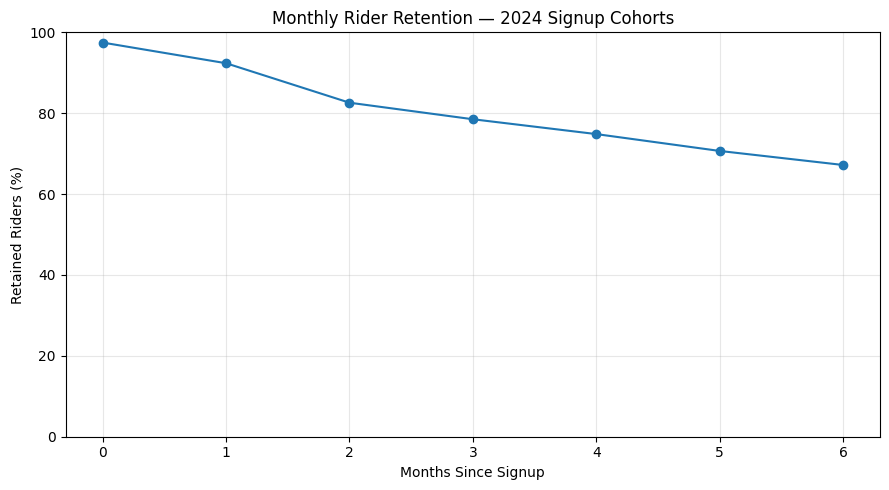

In [ ]:

# ==========================================
# COMPARABLE COHORT RETENTION SUMMARY
# Jan-Dec 2024 cohorts, months 0-6
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

comparable = retention_corrected[
    retention_corrected["signup_cohort"].between(
        "2024-01", "2024-12"
    )
].copy()

retention_summary = (
    comparable.groupby("month_number")
    .agg(
        cohort_size=("cohort_size", "sum"),
        active_riders=("active_riders", "sum")
    )
    .reset_index()
)

retention_summary["retention_pct"] = (
    100 * retention_summary["active_riders"]
    / retention_summary["cohort_size"]
).round(2)

print("WEIGHTED RETENTION — JAN-DEC 2024 COHORTS")
display(retention_summary)

# Retention chart
plt.figure(figsize=(9, 5))

plt.plot(
    retention_summary["month_number"],
    retention_summary["retention_pct"],
    marker="o"
)

plt.title("Monthly Rider Retention — 2024 Signup Cohorts")
plt.xlabel("Months Since Signup")
plt.ylabel("Retained Riders (%)")
plt.xticks(range(7))
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


WEIGHTED RETENTION — JAN-DEC 2024 COHORTS


,month_number,cohort_size,active_riders,retention_pct
0,0,9686,9441,97.47
1,1,9686,8946,92.36
2,2,9686,8001,82.60
3,3,9686,7604,78.51
4,4,9686,7249,74.84
5,5,9686,6845,70.67
6,6,9686,6509,67.20


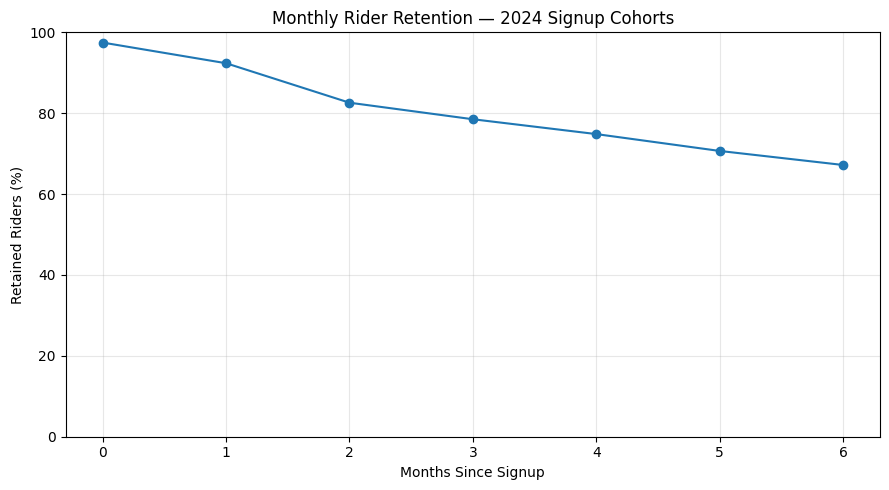

In [ ]:

# ==========================================
# COMPARABLE COHORT RETENTION SUMMARY
# Jan-Dec 2024 cohorts, months 0-6
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

comparable = retention_corrected[
    retention_corrected["signup_cohort"].between(
        "2024-01", "2024-12"
    )
].copy()

retention_summary = (
    comparable.groupby("month_number")
    .agg(
        cohort_size=("cohort_size", "sum"),
        active_riders=("active_riders", "sum")
    )
    .reset_index()
)

retention_summary["retention_pct"] = (
    100 * retention_summary["active_riders"]
    / retention_summary["cohort_size"]
).round(2)

print("WEIGHTED RETENTION — JAN-DEC 2024 COHORTS")
display(retention_summary)

# Retention chart
plt.figure(figsize=(9, 5))

plt.plot(
    retention_summary["month_number"],
    retention_summary["retention_pct"],
    marker="o"
)

plt.title("Monthly Rider Retention — 2024 Signup Cohorts")
plt.xlabel("Months Since Signup")
plt.ylabel("Retained Riders (%)")
plt.xticks(range(7))
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,city,total_events,failed_events,failure_rate_pct
0,Jaipur,487634,38268,7.85
1,Delhi NCR,768913,56528,7.35
2,Hyderabad,711930,47618,6.69
3,Pune,552910,27579,4.99
4,Bengaluru,825327,37630,4.56
5,Mumbai,530299,23581,4.45


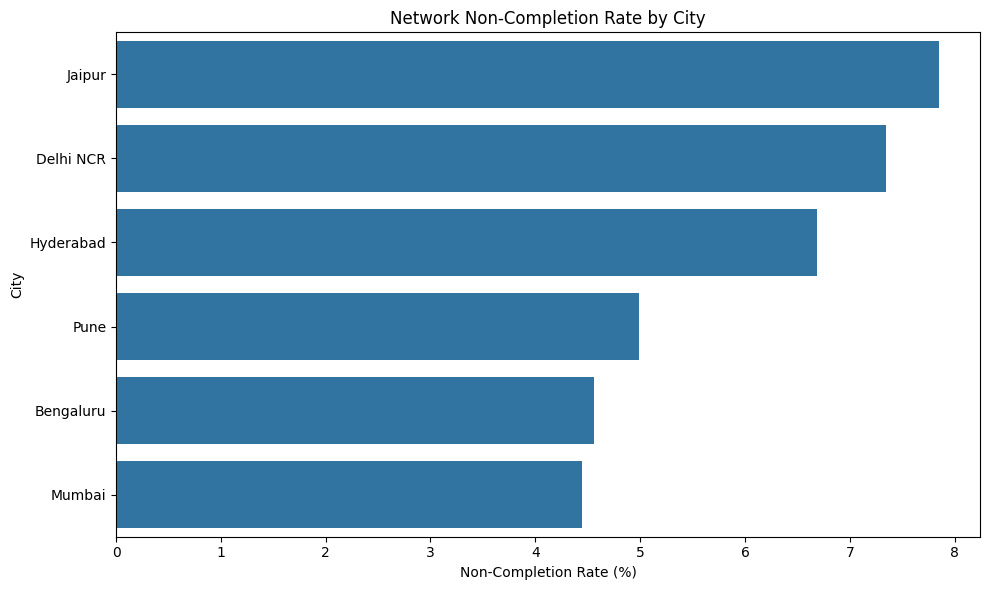

In [ ]:

# ==========================================
# CHART 1: NETWORK FAILURE RATE BY CITY
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

city_chart = con.execute("""
    SELECT
        s.city,
        COUNT(*) AS total_events,
        COUNT(*) FILTER (
            WHERE e.event_type <> 'swap_completed'
        ) AS failed_events,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type <> 'swap_completed'
            ) / COUNT(*),
            2
        ) AS failure_rate_pct
    FROM swap_events e
    JOIN stations s
        ON e.station_id = s.station_id
    GROUP BY s.city
    ORDER BY failure_rate_pct DESC
""").df()

display(city_chart)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=city_chart,
    x="failure_rate_pct",
    y="city"
)

plt.title("Network Non-Completion Rate by City")
plt.xlabel("Non-Completion Rate (%)")
plt.ylabel("City")
plt.tight_layout()
plt.show()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,charger_generation,total_events,failed_events,failure_rate_pct
0,Gen1,1822034,131736,7.23
1,Gen2,1682738,81445,4.84
2,Gen3,372241,18023,4.84


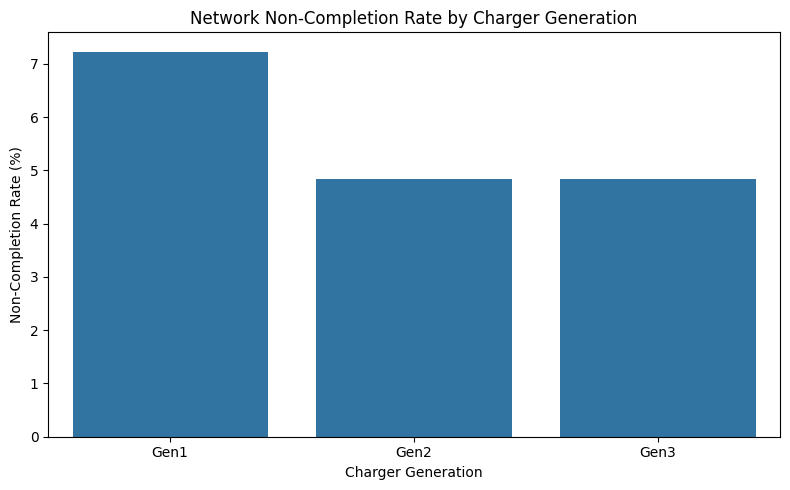

In [ ]:

# ==========================================
# CHART 2: FAILURE RATE BY CHARGER GENERATION
# ==========================================

generation_chart = con.execute("""
    SELECT
        s.charger_generation,
        COUNT(*) AS total_events,

        COUNT(*) FILTER (
            WHERE e.event_type <> 'swap_completed'
        ) AS failed_events,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type <> 'swap_completed'
            ) / COUNT(*),
            2
        ) AS failure_rate_pct

    FROM swap_events e

    JOIN stations s
        ON e.station_id = s.station_id

    GROUP BY s.charger_generation

    ORDER BY s.charger_generation
""").df()

display(generation_chart)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=generation_chart,
    x="charger_generation",
    y="failure_rate_pct"
)

plt.title("Network Non-Completion Rate by Charger Generation")
plt.xlabel("Charger Generation")
plt.ylabel("Non-Completion Rate (%)")

plt.tight_layout()
plt.show()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,station_id,city,charger_generation,total_events,failed_events,failure_rate_pct
0,STN-DEL-043,Delhi NCR,Gen1,49597,4271,8.61
1,STN-JAI-138,Jaipur,Gen1,48945,4242,8.67
2,STN-HYD-072,Hyderabad,Gen1,51765,4176,8.07
3,STN-DEL-050,Delhi NCR,Gen1,47060,4053,8.61
4,STN-JAI-141,Jaipur,Gen1,45594,3981,8.73
5,STN-JAI-137,Jaipur,Gen1,44371,3881,8.75
6,STN-HYD-070,Hyderabad,Gen1,49688,3768,7.58
7,STN-JAI-140,Jaipur,Gen1,44115,3733,8.46
8,STN-JAI-134,Jaipur,Gen1,42925,3612,8.41
9,STN-DEL-047,Delhi NCR,Gen1,41594,3509,8.44


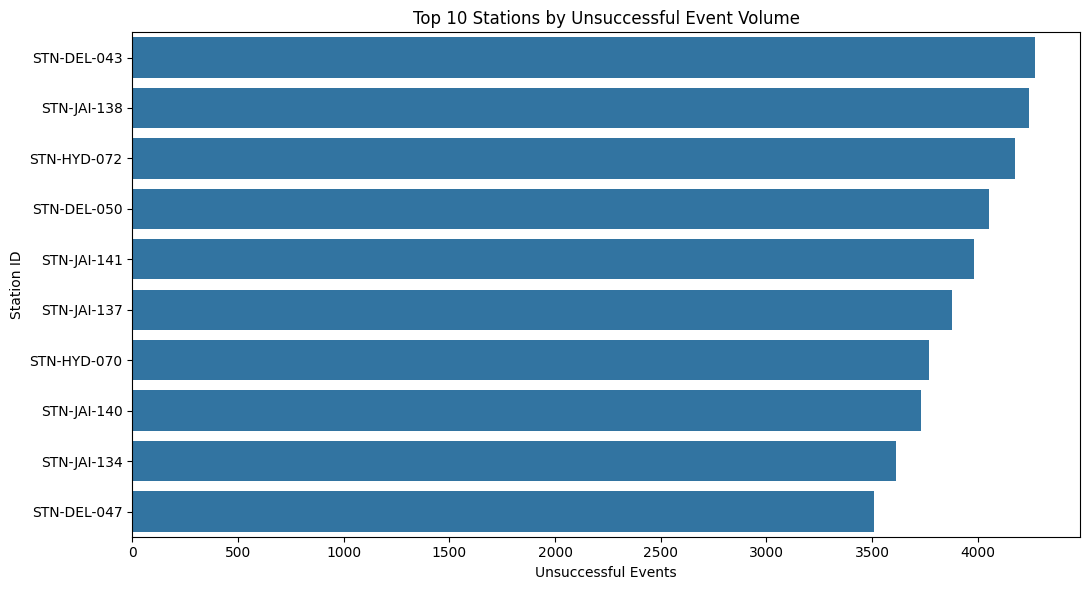

In [ ]:

# ==========================================
# CHART 3: TOP 10 STATIONS BY FAILED EVENTS
# ==========================================

station_chart = con.execute("""
    SELECT
        s.station_id,
        s.city,
        s.charger_generation,
        COUNT(*) AS total_events,

        COUNT(*) FILTER (
            WHERE e.event_type <> 'swap_completed'
        ) AS failed_events,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE e.event_type <> 'swap_completed'
            ) / COUNT(*),
            2
        ) AS failure_rate_pct

    FROM swap_events e

    JOIN stations s
        ON e.station_id = s.station_id

    GROUP BY
        s.station_id,
        s.city,
        s.charger_generation

    ORDER BY failed_events DESC

    LIMIT 10
""").df()

display(station_chart)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=station_chart,
    x="failed_events",
    y="station_id"
)

plt.title("Top 10 Stations by Unsuccessful Event Volume")
plt.xlabel("Unsuccessful Events")
plt.ylabel("Station ID")

plt.tight_layout()
plt.show()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,total_events,failed_events,failure_rate_pct
0,2024-01,110348,4858,4.40
1,2024-02,111531,4949,4.44
2,2024-03,123900,5456,4.40
3,2024-04,131818,8982,6.81
4,2024-05,146278,17950,12.27
5,2024-06,148888,15145,10.17
6,2024-07,158688,6864,4.33
7,2024-08,172295,7364,4.27
8,2024-09,195885,8583,4.38
9,2024-10,229901,10063,4.38


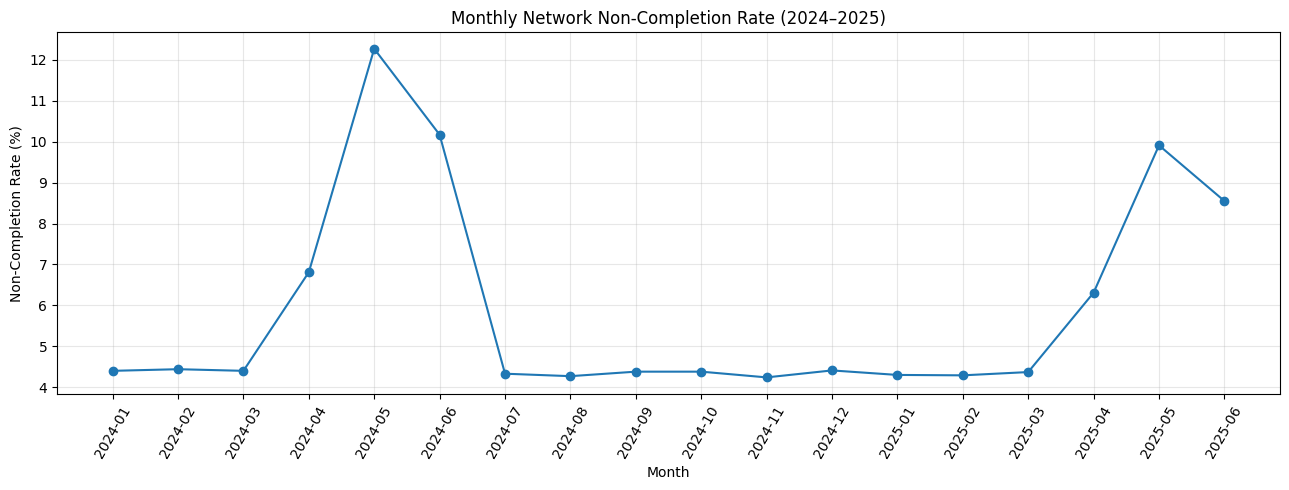

In [ ]:

# ==========================================
# CHART 4: MONTHLY NETWORK PERFORMANCE
# ==========================================

monthly_chart = con.execute("""
    SELECT
        STRFTIME(
            DATE_TRUNC(
                'month',
                TRY_CAST(event_ts AS TIMESTAMP)
            ),
            '%Y-%m'
        ) AS month,

        COUNT(*) AS total_events,

        COUNT(*) FILTER (
            WHERE event_type <> 'swap_completed'
        ) AS failed_events,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type <> 'swap_completed'
            ) / COUNT(*),
            2
        ) AS failure_rate_pct

    FROM swap_events

    WHERE TRY_CAST(event_ts AS TIMESTAMP) IS NOT NULL

    GROUP BY 1
    ORDER BY 1
""").df()

display(monthly_chart)

plt.figure(figsize=(13, 5))

plt.plot(
    monthly_chart["month"],
    monthly_chart["failure_rate_pct"],
    marker="o"
)

plt.title("Monthly Network Non-Completion Rate (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Non-Completion Rate (%)")

plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


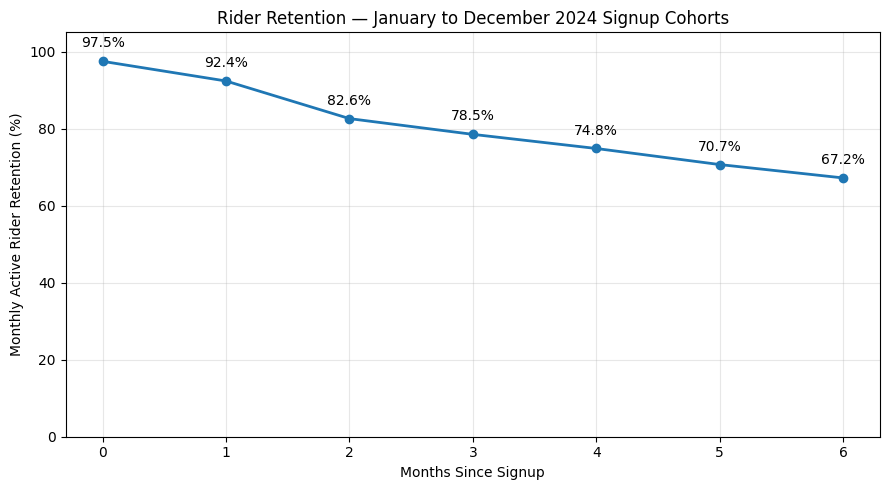

,month_number,cohort_size,active_riders,retention_pct
0,0,9686,9441,97.47
1,1,9686,8946,92.36
2,2,9686,8001,82.60
3,3,9686,7604,78.51
4,4,9686,7249,74.84
5,5,9686,6845,70.67
6,6,9686,6509,67.20


In [ ]:

# ==========================================
# CHART 5: RIDER RETENTION CURVE
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    retention_summary["month_number"],
    retention_summary["retention_pct"],
    marker="o",
    linewidth=2
)

for _, row in retention_summary.iterrows():
    plt.annotate(
        f'{row["retention_pct"]:.1f}%',
        (
            row["month_number"],
            row["retention_pct"]
        ),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.title(
    "Rider Retention — January to December 2024 Signup Cohorts"
)

plt.xlabel("Months Since Signup")
plt.ylabel("Monthly Active Rider Retention (%)")

plt.xticks(range(7))
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(retention_summary)


,charger_generation,observed_station_hours,zero_ready_battery_hours,zero_ready_hours_pct
0,Gen1,665860,15581,2.34
1,Gen2,688516,2887,0.42
2,Gen3,123952,328,0.26


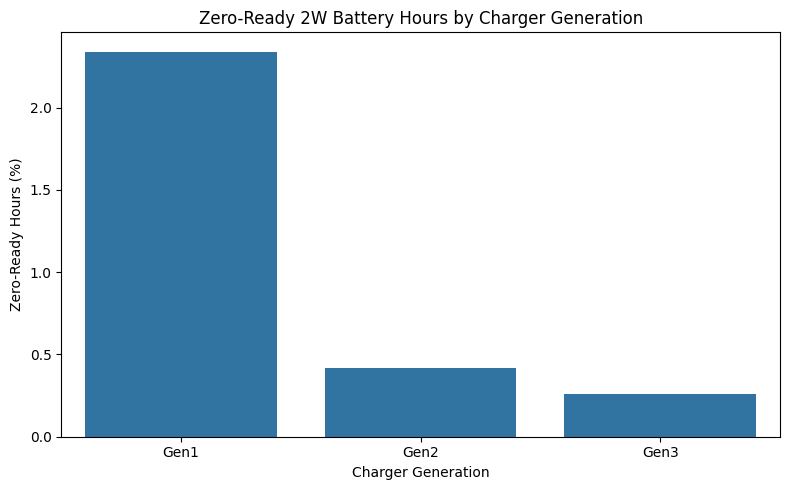

In [ ]:

# ==========================================
# CHART 6: ZERO-READY-BATTERY HOURS BY GENERATION
# ==========================================

availability_chart = con.execute("""
    SELECT
        s.charger_generation,

        COUNT(*) FILTER (
            WHERE TRY_CAST(h.charged_2w_min AS DOUBLE) IS NOT NULL
        ) AS observed_station_hours,

        COUNT(*) FILTER (
            WHERE TRY_CAST(h.charged_2w_min AS DOUBLE) = 0
        ) AS zero_ready_battery_hours,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE TRY_CAST(h.charged_2w_min AS DOUBLE) = 0
            )
            / NULLIF(
                COUNT(*) FILTER (
                    WHERE TRY_CAST(h.charged_2w_min AS DOUBLE) IS NOT NULL
                ),
                0
            ),
            2
        ) AS zero_ready_hours_pct

    FROM station_hourly_status h

    JOIN stations s
        ON h.station_id = s.station_id

    GROUP BY s.charger_generation
    ORDER BY s.charger_generation
""").df()

display(availability_chart)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=availability_chart,
    x="charger_generation",
    y="zero_ready_hours_pct"
)

plt.title("Zero-Ready 2W Battery Hours by Charger Generation")
plt.xlabel("Charger Generation")
plt.ylabel("Zero-Ready Hours (%)")

plt.tight_layout()
plt.show()


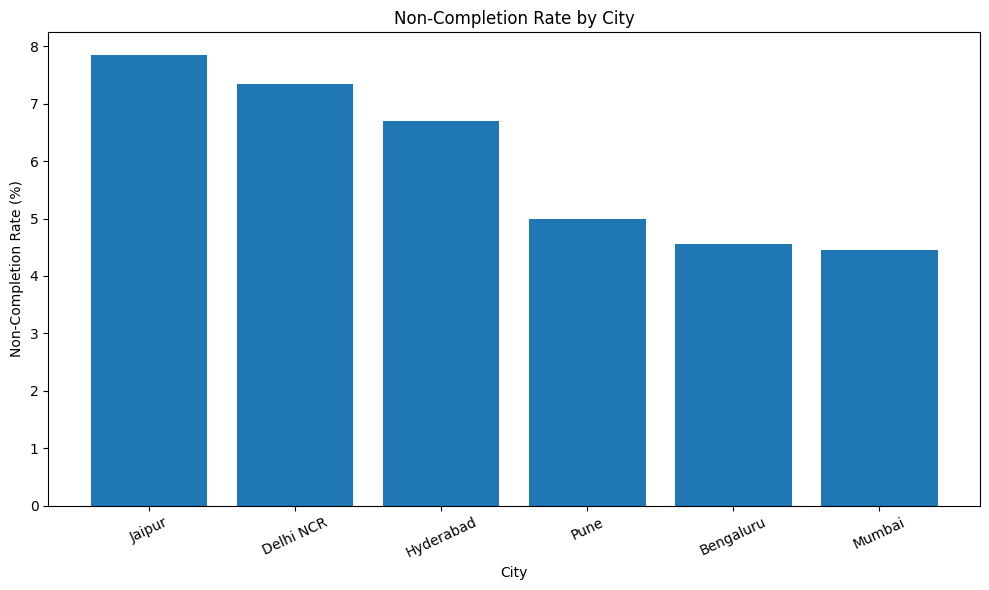

In [ ]:
import matplotlib.pyplot as plt

city_data = {
    "city": ["Jaipur", "Delhi NCR", "Hyderabad",
             "Pune", "Bengaluru", "Mumbai"],
    "non_completion_rate_pct": [7.85, 7.35, 6.69, 4.99, 4.56, 4.45]
}

plt.figure(figsize=(10, 6))

plt.bar(
    city_data["city"],
    city_data["non_completion_rate_pct"]
)

plt.title("Non-Completion Rate by City")
plt.xlabel("City")
plt.ylabel("Non-Completion Rate (%)")
plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    "/content/chart_1_city_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

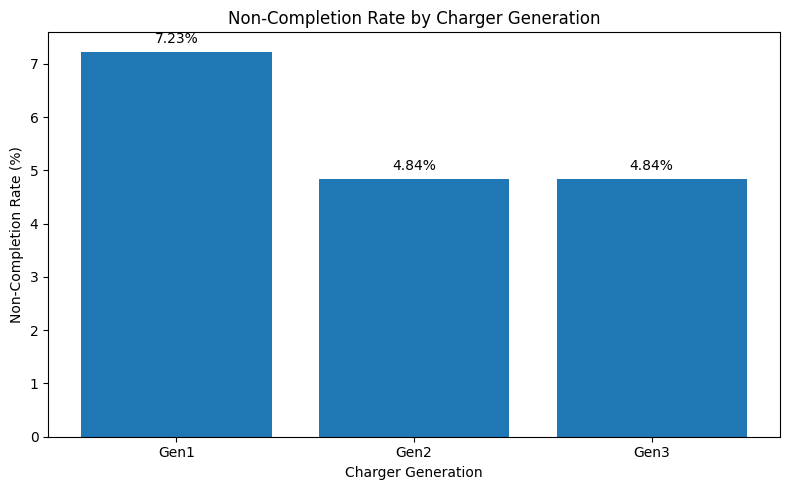

In [ ]:
import matplotlib.pyplot as plt

generation_data = {
    "generation": ["Gen1", "Gen2", "Gen3"],
    "non_completion_rate_pct": [7.23, 4.84, 4.84]
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    generation_data["generation"],
    generation_data["non_completion_rate_pct"]
)

plt.title("Non-Completion Rate by Charger Generation")
plt.xlabel("Charger Generation")
plt.ylabel("Non-Completion Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=4)

plt.tight_layout()

plt.savefig(
    "/content/chart_2_generation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

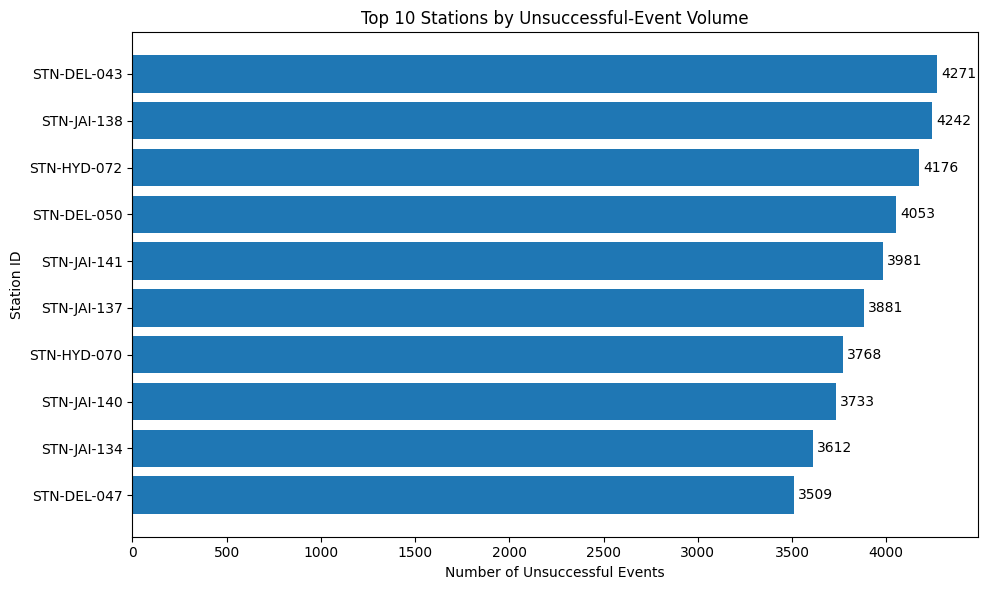

In [ ]:
import matplotlib.pyplot as plt

station_data = {
    "station": [
        "STN-DEL-043",
        "STN-JAI-138",
        "STN-HYD-072",
        "STN-DEL-050",
        "STN-JAI-141",
        "STN-JAI-137",
        "STN-HYD-070",
        "STN-JAI-140",
        "STN-JAI-134",
        "STN-DEL-047"
    ],
    "unsuccessful_events": [
        4271, 4242, 4176, 4053, 3981,
        3881, 3768, 3733, 3612, 3509
    ]
}

plt.figure(figsize=(10, 6))

bars = plt.barh(
    station_data["station"][::-1],
    station_data["unsuccessful_events"][::-1]
)

plt.title("Top 10 Stations by Unsuccessful-Event Volume")
plt.xlabel("Number of Unsuccessful Events")
plt.ylabel("Station ID")

plt.bar_label(bars, padding=3, fmt="%d")
plt.tight_layout()

plt.savefig(
    "/content/chart_3_top_stations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

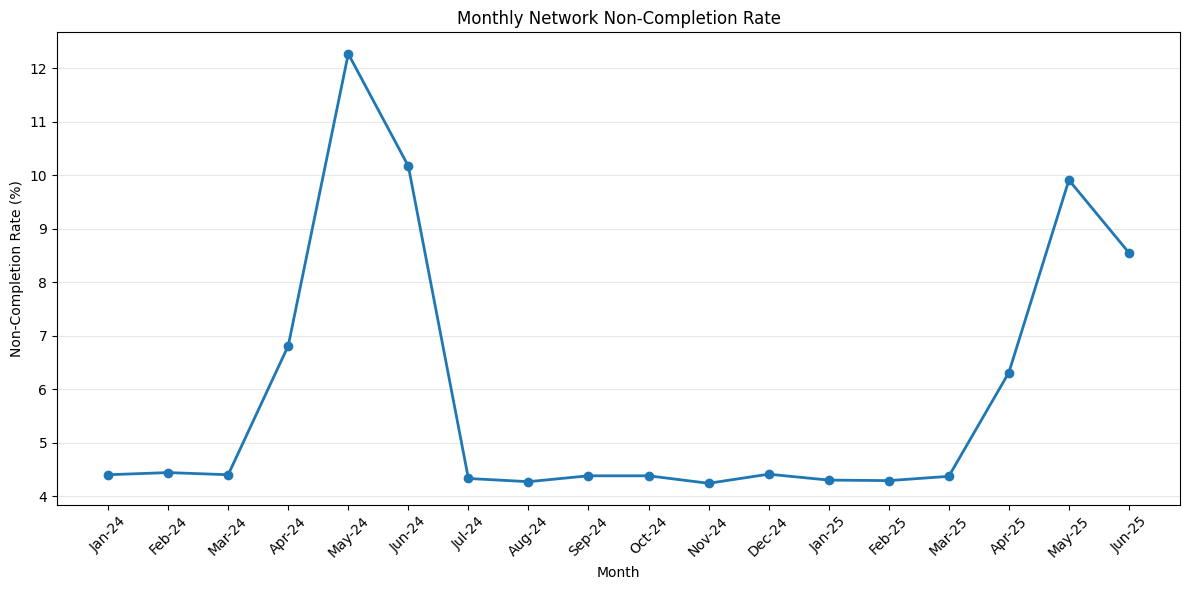

In [ ]:
import matplotlib.pyplot as plt

monthly_data = {
    "month": [
        "Jan-24", "Feb-24", "Mar-24", "Apr-24",
        "May-24", "Jun-24", "Jul-24", "Aug-24",
        "Sep-24", "Oct-24", "Nov-24", "Dec-24",
        "Jan-25", "Feb-25", "Mar-25", "Apr-25",
        "May-25", "Jun-25"
    ],
    "rate": [
        4.40, 4.44, 4.40, 6.81, 12.27, 10.17,
        4.33, 4.27, 4.38, 4.38, 4.24, 4.41,
        4.30, 4.29, 4.37, 6.31, 9.91, 8.55
    ]
}

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_data["month"],
    monthly_data["rate"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Network Non-Completion Rate")
plt.xlabel("Month")
plt.ylabel("Non-Completion Rate (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/content/chart_4_monthly_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

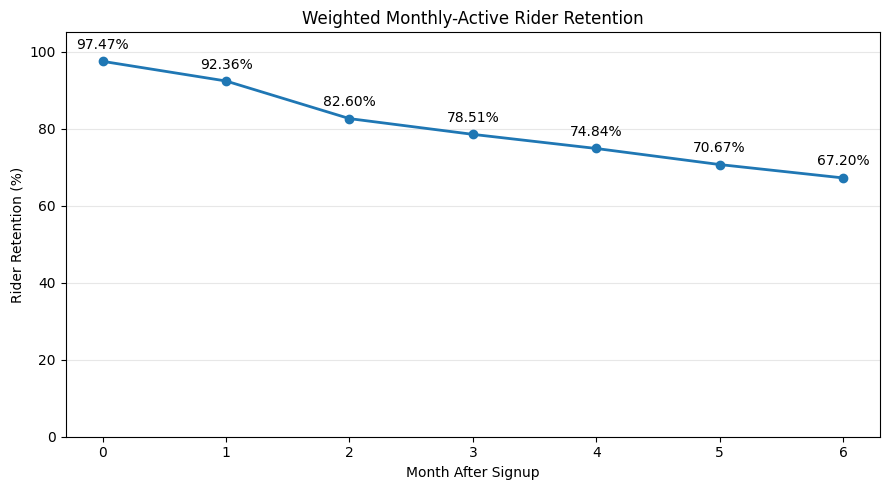

In [ ]:
import matplotlib.pyplot as plt

retention_data = {
    "month": [0, 1, 2, 3, 4, 5, 6],
    "retention_pct": [
        97.47, 92.36, 82.60, 78.51,
        74.84, 70.67, 67.20
    ]
}

plt.figure(figsize=(9, 5))

plt.plot(
    retention_data["month"],
    retention_data["retention_pct"],
    marker="o",
    linewidth=2
)

plt.title("Weighted Monthly-Active Rider Retention")
plt.xlabel("Month After Signup")
plt.ylabel("Rider Retention (%)")

plt.xticks(range(7))
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

for x, y in zip(
    retention_data["month"],
    retention_data["retention_pct"]
):
    plt.annotate(
        f"{y:.2f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "/content/chart_5_retention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

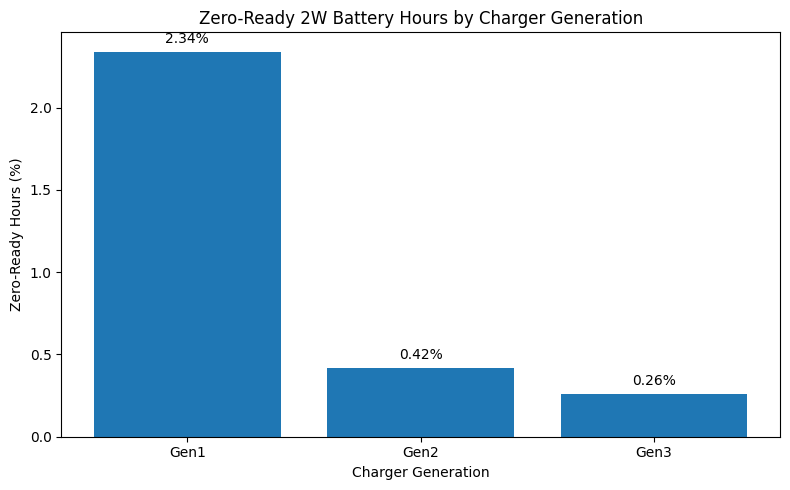

In [ ]:
import matplotlib.pyplot as plt

availability_data = {
    "generation": ["Gen1", "Gen2", "Gen3"],
    "zero_ready_pct": [2.34, 0.42, 0.26]
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    availability_data["generation"],
    availability_data["zero_ready_pct"]
)

plt.title("Zero-Ready 2W Battery Hours by Charger Generation")
plt.xlabel("Charger Generation")
plt.ylabel("Zero-Ready Hours (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=4)

plt.tight_layout()

plt.savefig(
    "/content/chart_6_battery_availability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()